# 1. Comprensión de los datos

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
from IPython.display import display
import unicodedata
import matplotlib.pyplot as plt

In [2]:
REQUIRED_FILES = (
    "Afluencia Diaria del Metro (Desglosada).csv",
    "Afluencia Diaria del Metrobús (Desglosada).csv",
    "Afluencia Preliminar en Transporte Publico (histórico).csv",
    "Diccionario Afluencia Desglosada - MB.csv",
    "Diccionario de datos (Afluencia desglosada).csv",
    "Diccionario de datos ingresos STCM.xlsx",
    "Ingresos del Sistema de Transporte Colectivo Metro.csv",
    "Viajes diarios del sistema Ecobici.csv",
    "Viajes Ecobico 2026-01.csv",
    "Ubicación de estaciones ecobici.csv",
    "Viajes mensuales desglosados del sistema Ecobici.csv",
)

def localizar_datos() -> Path:
    """Devuelve la carpeta datasets/ de Movilidad-Urbana-del-Sistema-de-Transporte-CDMX o indica cómo prepararla."""
    candidatos = []
    definida = os.environ.get("MOVILIDAD_DATA_DIR")
    if definida:
        candidatos.append(Path(definida).expanduser())

    ubicacion = Path.cwd().resolve()
    for base in (ubicacion, *ubicacion.parents):
        candidatos.extend([
            base / "Movilidad-Urbana-del-Sistema-de-Transporte-CDMX" / "Datasets",
            base / "Datasets",
            base.parent / "Movilidad-Urbana-del-Sistema-de-Transporte-CDMX" / "Datasets",
        ])

    for ruta in candidatos:
        if ruta.is_dir() and all((ruta / nombre).is_file() for nombre in REQUIRED_FILES):
            return ruta
    raise FileNotFoundError(
        "No encontré los CSV de Movilidad-Urbana. Ejecuta 'git clone "
        "https://github.com/Juan-Gallegos7/Movilidad-Urbana-del-Sistema-de-Transporte-CDMX' en la "
        "carpeta del curso y coloca este notebook en una carpeta hermana "
        "del repositorio; o establece MOVILIDAD_DATA_DIR con la ruta a datasets/."
    )


DATA_DIR = localizar_datos()
print("Datos encontrados en:", DATA_DIR)

Datos encontrados en: /Users/arantxaalva21/Diplomado_2026/Movilidad-Urbana-del-Sistema-de-Transporte-CDMX/Datasets


In [3]:

import chardet

with open(
    DATA_DIR / "Afluencia Diaria del Metro (Desglosada).csv",
    "rb"
) as f:
    resultado = chardet.detect(f.read(100000))

print(resultado)

{'encoding': 'utf-8', 'confidence': 0.9041276, 'language': 'pt', 'mime_type': 'text/plain'}


In [4]:
Afluencia_Metro = pd.read_csv(DATA_DIR / "Afluencia Diaria del Metro (Desglosada).csv")
Afluencia_Metrobus = pd.read_csv(DATA_DIR / "Afluencia Diaria del Metrobús (Desglosada).csv")
Afluencia_TP_historico = pd.read_csv(DATA_DIR / "Afluencia Preliminar en Transporte Publico (histórico).csv")
Ingresos_SCTM = pd.read_csv(DATA_DIR / "Ingresos del Sistema de Transporte Colectivo Metro.csv")
Dic_ingresos_SCTM = pd.read_excel(DATA_DIR / "Diccionario de datos ingresos STCM.xlsx")

for nombre, tabla in {
    "Afluencia_Metro": Afluencia_Metro,
    "Afluencia_Metrobus": Afluencia_Metrobus,
    "Afluencia_TP_historico": Afluencia_TP_historico,
    "Dic_ingresos_SCTM": Dic_ingresos_SCTM,
    "Ingresos_SCTM": Ingresos_SCTM,
}.items():
    print(f"{nombre:12s}: {len(tabla):>8,} filas × {tabla.shape[1]:>2} columnas")

display(Afluencia_Metro.head(3))
display(Afluencia_Metrobus.head(3))
display(Afluencia_TP_historico.head(3))
display(Dic_ingresos_SCTM.head())
display(Ingresos_SCTM.head(3))

Afluencia_Metro: 1,227,915 filas ×  7 columnas
Afluencia_Metrobus:   29,386 filas ×  6 columnas
Afluencia_TP_historico:   18,714 filas ×  8 columnas
Dic_ingresos_SCTM:       14 filas ×  3 columnas
Ingresos_SCTM:  159,948 filas ×  4 columnas


,fecha,mes,anio,linea,estacion,tipo_pago,afluencia
0,2021-01-01,Enero,2021,LÃ­nea 1,Balbuena,Boleto,1848
1,2021-01-01,Enero,2021,LÃ­nea 1,Balbuena,Prepago,790
2,2021-01-01,Enero,2021,LÃ­nea 1,Balbuena,Gratuidad,325


,fecha,mes,anio,linea,tipo_pago,afluencia
0,2021-01-01,Enero,2021,Línea 1,Prepago,39122.0
1,2021-01-01,Enero,2021,Línea 1,Gratuidad,3528.0
2,2021-01-01,Enero,2021,Línea 2,Prepago,23669.0


,id,organismo,linea_servicio,dia,fecha,afluencia_tarjeta,afluencia_boleto,afluencia_total_preliminar
0,1,Ecobici,NaN,Domingo,2020-03-01,NaN,NaN,"11,238"
1,2,Ecobici,NaN,Lunes,2020-03-02,NaN,NaN,"29,475"
2,3,Ecobici,NaN,Martes,2020-03-03,NaN,NaN,"31,855"


,Variable,Descripción Variable,Etiqueta de Datos Abiertos
0,Fecha,Indica el día en el que se recibió este ingreso.,FECHA
1,Tipo de ingreso,Campo que especifíca si el ingreso fue por ven...,TIPO_INGRESO
2,Línea 1,Indica los ingresos que recibió la ciudad para...,LINEA_1
3,Línea 2,Indica los ingresos que recibió la ciudad para...,LINEA_2
4,Línea 3,Indica los ingresos que recibió la ciudad para...,LINEA_3


,fecha,tipo_ingreso,linea,ingreso
0,2012-01-01,Boletos,Línea 1,648825.0
1,2012-01-01,Boletos,Línea 2,657120.0
2,2012-01-01,Boletos,Línea 3,466803.0


In [5]:
print("Registros por línea (Metro): ", Afluencia_Metro.groupby("linea").size())
print("Registros por mes (Metro): ", Afluencia_Metro.groupby("mes").size())
print("Registros por mes (Año): ", Afluencia_Metro.groupby("anio").size())
print("Registros por mes (Estacion): ", Afluencia_Metro.groupby("estacion").size())
print("Registros por mes (tipo_pago): ", Afluencia_Metro.groupby("tipo_pago").size())

Registros por línea (Metro):  linea
Linea 1      73080
Linea 12     73080
Linea 2      87696
Linea 3      76734
Linea 4      36540
Linea 5      47502
Linea 6      40194
Linea 7      51156
Linea 8      69426
Linea 9      43848
Linea A      36540
Linea B      76734
LÃ­nea 1     52860
LÃ­nea 12    52860
LÃ­nea 2     63432
LÃ­nea 3     55503
LÃ­nea 4     26430
LÃ­nea 5     34359
LÃ­nea 6     29073
LÃ­nea 7     37002
LÃ­nea 8     50217
LÃ­nea 9     31716
LÃ­nea A     26430
LÃ­nea B     55503
dtype: int64
Registros por mes (Metro):  mes
Abril         105300
Agosto        108810
Diciembre      90675
Enero         108810
Febrero        98865
Julio         108810
Junio         105300
Marzo         108810
Mayo          108810
Noviembre      87750
Octubre        90675
Septiembre    105300
dtype: int64
Registros por mes (Año):  anio
2021    213525
2022    213525
2023    213525
2024    214110
2025    213525
2026    159705
dtype: int64
Registros por mes (Estacion):  estacion
Acatitla                

In [6]:
print("Registros por línea (Metrobus): ", Afluencia_Metrobus.groupby("linea").size())
print("Registros por mes (Metrobus): ", Afluencia_Metrobus.groupby("mes").size())
print("Registros por Año (Metrobus): ", Afluencia_Metrobus.groupby("anio").size())
print("Registros por Tipo pago (Metrobus): ", Afluencia_Metrobus.groupby("tipo_pago").size())

Registros por línea (Metrobus):  linea
Linea 1     184
Linea 2     184
Linea 3     184
Linea 4     184
Linea 5     184
Linea 6     184
Linea 7     184
Línea 1    3284
Línea 2    3284
Línea 3    3284
Línea 4    3284
Línea 5    3284
Línea 6    3284
Línea 7    3284
linea 1     730
linea 2     730
linea 3     730
linea 4     730
linea 5     730
linea 6     730
linea 7     730
dtype: int64
Registros por mes (Metrobus):  mes
Abril         2520
Agosto        2604
Diciembre     2170
Enero         2604
Febrero       2366
Julio         2604
Junio         2520
Marzo         2604
Mayo          2604
Noviembre     2100
Octubre       2170
Septiembre    2520
dtype: int64
Registros por Año (Metrobus):  anio
2021    5110
2022    5110
2023    5110
2024    5124
2025    5110
2026    3822
dtype: int64
Registros por Tipo pago (Metrobus):  tipo_pago
Gratuidad    14693
Prepago      14693
dtype: int64


In [7]:
print("Registros por organismo (Metro): ", Afluencia_TP_historico.groupby("organismo").size())
print("Registros por servicio (Metro): ", Afluencia_TP_historico.groupby("linea_servicio").size())
print("Registros por dia (Año): ", Afluencia_TP_historico.groupby("dia").size())

Registros por organismo (Metro):  organismo
Ecobici             489
Metrobús           3461
RTP                3671
STC                5868
STE-Cablebús        121
STE-Tren Ligero     489
STE-Trolebús       4126
Suburbano           489
dtype: int64
Registros por servicio (Metro):  linea_servicio
Atenea                                                489
Eco Atenea                                            489
Ecobús                                                489
Expreso                                               489
Expreso Directo                                       489
L1                                                   1467
L1 Campos Revolución-Tlalpexco                        121
L1 Eje Central                                        489
L12                                                   489
L2                                                    978
L2 Eje 2 sur                                          489
L3                                                    978
L3 Eje 

# 2. Exploración y estadística descriptiva (EDA)



# 3. Calidad, limpieza y transformación

## 3.1 Limpieza de los datos

In [8]:
ROOT = DATA_DIR.parent
OUT_DATA = ROOT / "data" / "processed"
OUT_FIG = ROOT / "resultados" / "figuras"
OUT_TAB = ROOT / "resultados" / "tablas"
for carpeta in (OUT_DATA, OUT_FIG, OUT_TAB):
    carpeta.mkdir(parents=True, exist_ok=True)

registro = []

def log_decision(paso, tabla, variable, criterio, afectadas, accion, limitacion):
    registro.append({
        "paso": paso, "tabla": tabla, "variable": variable, "criterio": criterio,
        "filas_afectadas": int(afectadas), "accion": accion, "limitacion": limitacion,
    })

metro_raw = Afluencia_Metro.copy()
metro = metro_raw.copy()
metrobus = Afluencia_Metrobus.copy()
ingresos = Ingresos_SCTM.copy()
historico = Afluencia_TP_historico.copy()
ecobici = pd.read_csv(
    DATA_DIR / "Viajes Ecobico 2026-01.csv",
    dtype={"Ciclo_Estacion_Retiro": str, "Ciclo_EstacionArribo": str},
    low_memory=False,
)


In [9]:
def limpieza(df, llave=None):
    filas = []
    for col in df.columns:
        s = df[col]
        filas.append({
            "variable": col,
            "tipo": str(s.dtype),
            "n_faltantes": int(s.isna().sum()),
            "pct_faltantes": round(100 * s.isna().mean(), 2),
            "n_unicos": int(s.nunique(dropna=True)),
        })
    res = pd.DataFrame(filas)
    print(f"Duplicados exactos: {df.duplicated().sum():,}", end="")
    if llave:
        print(f" | duplicados en la llave {llave}: {df.duplicated(llave).sum():,}")
    else:
        print()
    return res

print("METRO");    display(limpieza(metro, ["fecha", "linea", "estacion", "tipo_pago"]))
print("METROBÚS"); display(limpieza(metrobus, ["fecha", "linea", "tipo_pago"]))
print("INGRESOS"); display(limpieza(ingresos, ["fecha", "linea", "tipo_ingreso"]))
print("ECOBICI");  display(limpieza(ecobici))

METRO
Duplicados exactos: 0 | duplicados en la llave ['fecha', 'linea', 'estacion', 'tipo_pago']: 0


,variable,tipo,n_faltantes,pct_faltantes,n_unicos
0,fecha,object,0,0.0,2099
1,mes,object,0,0.0,12
2,anio,int64,0,0.0,6
3,linea,object,0,0.0,24
4,estacion,object,0,0.0,168
5,tipo_pago,object,0,0.0,3
6,afluencia,int64,0,0.0,48199


METROBÚS
Duplicados exactos: 0 | duplicados en la llave ['fecha', 'linea', 'tipo_pago']: 0


,variable,tipo,n_faltantes,pct_faltantes,n_unicos
0,fecha,object,0,0.0,2099
1,mes,object,0,0.0,12
2,anio,int64,0,0.0,6
3,linea,object,0,0.0,21
4,tipo_pago,object,0,0.0,2
5,afluencia,float64,0,0.0,25257


INGRESOS
Duplicados exactos: 11 | duplicados en la llave ['fecha', 'linea', 'tipo_ingreso']: 12


,variable,tipo,n_faltantes,pct_faltantes,n_unicos
0,fecha,object,0,0.00,4230
1,tipo_ingreso,object,0,0.00,5
2,linea,object,0,0.00,12
3,ingreso,float64,1067,0.67,88998


ECOBICI
Duplicados exactos: 0


,variable,tipo,n_faltantes,pct_faltantes,n_unicos
0,Genero_Usuario,object,1,0.00,4
1,Edad_Usuario,float64,79,0.01,75
2,Bici,int64,0,0.00,7391
3,Ciclo_Estacion_Retiro,object,0,0.00,677
4,Fecha_Retiro,object,0,0.00,42
5,Hora_Retiro,object,0,0.00,69706
6,Ciclo_EstacionArribo,object,0,0.00,677
7,Fecha_Arribo,object,0,0.00,31
8,Hora_Arribo,object,0,0.00,70772


In [10]:
# Rangos de las variables numéricas y valores 
rangos = pd.DataFrame({
    "metro_afluencia": metro["afluencia"].describe(),
    "metrobus_afluencia": metrobus["afluencia"].describe(),
    "ingreso": ingresos["ingreso"].describe(),
    "ecobici_edad": ecobici["Edad_Usuario"].describe(),
}).round(1)
display(rangos)

print("Negativos  -> metro:", (metro["afluencia"] < 0).sum(),
      "| metrobús:", (metrobus["afluencia"] < 0).sum(),
      "| ingresos:", (ingresos["ingreso"] < 0).sum())
print("Ceros      -> metro:", f"{(metro['afluencia'] == 0).sum():,}",
      f"({100 * (metro['afluencia'] == 0).mean():.1f} % de las filas)")
print("Afluencia Metrobús no entera:", (metrobus["afluencia"] % 1 != 0).sum())

,metro_afluencia,metrobus_afluencia,ingreso,ecobici_edad
count,1227915.0,29386.0,158881.0,1525223.0
mean,5129.7,90640.8,414608.9,34.6
std,8758.5,105655.8,508479.6,9.8
min,0.0,42.0,0.0,16.0
25%,7.0,10865.0,2680.0,28.0
50%,2045.0,35209.5,233225.0,33.0
75%,6052.0,148693.8,662765.0,40.0
max,119577.0,586643.0,8337195.0,100.0


Negativos  -> metro: 0 | metrobús: 0 | ingresos: 0
Ceros      -> metro: 303,400 (24.7 % de las filas)
Afluencia Metrobús no entera: 57


In [11]:
def reparar_mojibake(texto):
    # Revierte la doble codificación UTF-8 -> Latin-1 (ej. 'PantitlÃ¡n' -> 'Pantitlán').
    if isinstance(texto, str) and ("Ã" in texto or "Â" in texto):
        try:
            return texto.encode("latin-1").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            return texto
    return texto

def clave_sin_acentos(texto):
    # Clave de comparación: sin acentos, minúsculas y sin espacios extra.
    t = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return " ".join(t.lower().split())

def estandarizar_linea(texto):
    # Cualquier variante ('LÃ­nea 1', 'Linea 1', 'linea 1') -> 'Línea 1'.
    t = reparar_mojibake(texto)
    sufijo = clave_sin_acentos(t).replace("linea", "", 1).strip().upper()
    return f"Línea {sufijo}"

# Diagnóstico antes de corregir
antes = {
    "metro_lineas": metro["linea"].nunique(),
    "metro_estaciones": metro["estacion"].nunique(),
    "metrobus_lineas": metrobus["linea"].nunique(),
    "ingresos_tipos": ingresos["tipo_ingreso"].nunique(),
}
n_mojibake = metro["estacion"].astype(str).str.contains("Ã").sum()
print("Ejemplos con mojibake:",
      metro.loc[metro["estacion"].str.contains("Ã"), "estacion"].unique()[:5])

Ejemplos con mojibake: ['Boulevard Puerto AÃ©reo' 'CuauhtÃ©moc' 'GÃ³mez FarÃ\xadas'
 'Isabel la CatÃ³lica' 'JuanacatlÃ¡n']


In [12]:
# 1) Líneas: misma forma en Metro, Metrobús e Ingresos
filas_linea_metro = (metro["linea"] != metro["linea"].map(estandarizar_linea)).sum()
metro["linea"] = metro["linea"].map(estandarizar_linea)
filas_linea_mb = (metrobus["linea"] != metrobus["linea"].map(estandarizar_linea)).sum()
metrobus["linea"] = metrobus["linea"].map(estandarizar_linea)
ingresos["linea"] = ingresos["linea"].map(estandarizar_linea)

# 2) Estaciones: reparar mojibake y unificar variantes que solo difieren en acentos/mayúsculas
metro["estacion"] = metro["estacion"].map(reparar_mojibake).str.strip()
conteo = metro.groupby("estacion").size()
clave = conteo.index.to_series().map(clave_sin_acentos)
# Para cada clave elegimos la escritura más completa: más acentos, luego más mayúsculas
cand = pd.DataFrame({"estacion": conteo.index, "clave": clave.values})
cand["n_acentos"] = cand["estacion"].map(lambda t: sum(not ch.isascii() for ch in t))
cand["n_mayus"] = cand["estacion"].map(lambda t: sum(ch.isupper() for ch in t))
canonica = (
    cand.sort_values(["n_acentos", "n_mayus"], ascending=False)
    .drop_duplicates("clave")
    .set_index("clave")["estacion"]
)
variantes = {e: canonica[k] for e, k in clave.items() if e != canonica[k]}
print("Variantes unificadas:", variantes)
filas_variantes = metro["estacion"].isin(variantes.keys()).sum()
metro["estacion"] = metro["estacion"].replace(variantes)

# 3) Tipo de ingreso: un solo nombre para el pago con QR
filas_qr = (ingresos["tipo_ingreso"] == "QR/Validador").sum()
ingresos["tipo_ingreso"] = ingresos["tipo_ingreso"].replace({"QR/Validador": "QR/Validación"})

despues = {
    "metro_lineas": metro["linea"].nunique(),
    "metro_estaciones": metro["estacion"].nunique(),
    "metrobus_lineas": metrobus["linea"].nunique(),
    "ingresos_tipos": ingresos["tipo_ingreso"].nunique(),
}
display(pd.DataFrame({"antes": antes, "después": despues}))

log_decision("D1", "metro", "linea", "mojibake y 'Linea' sin acento según el periodo",
             filas_linea_metro, "estandarizar a 'Línea X'", "ninguna: es la misma línea")
log_decision("D1", "metro", "estacion", "mojibake y variantes de acentos/mayúsculas",
             n_mojibake + filas_variantes, "reparar codificación y unificar a la escritura con acentos y mayúsculas",
             "la unificación supone que nombres iguales sin acentos son la misma estación")
log_decision("D1", "metrobus", "linea", "tres escrituras distintas según el periodo",
             filas_linea_mb, "estandarizar a 'Línea X'", "ninguna")
log_decision("D1", "ingresos", "tipo_ingreso", "'QR/Validador' renombrado por la fuente en dic-2022",
             filas_qr, "unificar en 'QR/Validación'",
             "supone que el cambio fue solo de nombre y no de concepto de cobro")

Variantes unificadas: {'Gómez Farias': 'Gómez Farías', 'Peñón viejo': 'Peñón Viejo'}


,antes,después
metro_lineas,24,12
metro_estaciones,168,163
metrobus_lineas,21,7
ingresos_tipos,5,4


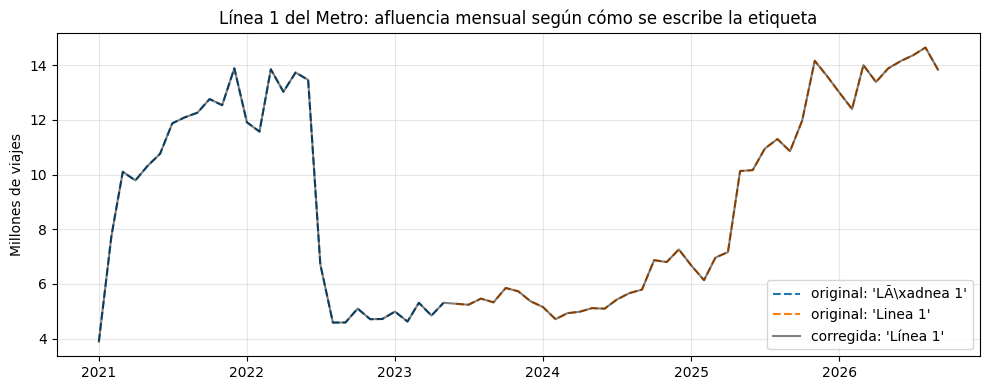

In [13]:
# Consecuencia: serie mensual de la Línea 1 con las etiquetas originales vs. corregidas
original = metro_raw.assign(mes_ = pd.to_datetime(metro_raw["fecha"]).dt.to_period("M"))
corregida = metro.assign(mes_ = pd.to_datetime(metro["fecha"]).dt.to_period("M"))

fig, ax = plt.subplots(figsize=(10, 4))
etiquetas_l1 = [e for e in original["linea"].unique() if clave_sin_acentos(reparar_mojibake(e)) == "linea 1"]
for e in etiquetas_l1:
    s = original[original["linea"] == e].groupby("mes_")["afluencia"].sum() / 1e6
    ax.plot(s.index.to_timestamp(), s.values, "--", label=f"original: {e!r}")
s = corregida[corregida["linea"] == "Línea 1"].groupby("mes_")["afluencia"].sum() / 1e6
ax.plot(s.index.to_timestamp(), s.values, color="black", lw=1.5, alpha=.5, label="corregida: 'Línea 1'")
ax.set_title("Línea 1 del Metro: afluencia mensual según cómo se escribe la etiqueta")
ax.set_ylabel("Millones de viajes"); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT_FIG / "D1_etiquetas_linea1.png", dpi=150); plt.show()

In [14]:
metro["fecha"] = pd.to_datetime(metro["fecha"], format="%Y-%m-%d")

estacion_dia = metro.groupby(["fecha", "linea", "estacion"], as_index=False)["afluencia"].sum()
estacion_dia["en_servicio"] = estacion_dia["afluencia"] > 0
print(f"Estación-día con afluencia total 0: {(~estacion_dia['en_servicio']).sum():,} "
      f"de {len(estacion_dia):,} ({100 * (~estacion_dia['en_servicio']).mean():.1f} %)")

# Periodos en que una LÍNEA completa suma cero
linea_dia = metro.groupby(["fecha", "linea"])["afluencia"].sum().reset_index()
cerradas = linea_dia[linea_dia["afluencia"] == 0]
resumen_cierres = cerradas.groupby("linea")["fecha"].agg(dias="count", desde="min", hasta="max")
display(resumen_cierres)

# Estaciones con más días en cero
display(estacion_dia[~estacion_dia["en_servicio"]]
        .groupby(["linea", "estacion"]).size().sort_values(ascending=False).head(10)
        .to_frame("dias_en_cero"))

Estación-día con afluencia total 0: 29,764 de 409,305 (7.3 %)


,dias,desde,hasta
linea,,,
Línea 1,16,2021-01-09,2021-01-24
Línea 12,621,2021-05-04,2023-01-14
Línea 2,30,2021-01-09,2021-02-07
Línea 3,23,2021-01-09,2021-01-31
Línea 4,3,2021-01-09,2021-01-11
Línea 5,3,2021-01-09,2021-01-11
Línea 6,3,2021-01-09,2021-01-11


dias_en_cero
linea    estacion                        
Línea 12 Tlaltenco                   1000
         Zapotitlán                   999
         Nopalera                     998
         Olivos                       997
         Tezonco                      995
         Tláhuac                      989
Línea 1  Isabel la Católica           813
         Salto del Agua               813
Línea 12 Periférico Oriente           805
         Lomas Estrella               805

In [15]:
# Sensibilidad: afluencia diaria promedio por estación, con y sin días sin servicio
con = estacion_dia.groupby("linea")["afluencia"].agg(media_con_ceros="mean", mediana_con_ceros="median")
sin = (estacion_dia[estacion_dia["en_servicio"]].groupby("linea")["afluencia"]
       .agg(media_en_servicio="mean", mediana_en_servicio="median"))
pct = (~estacion_dia["en_servicio"]).groupby(estacion_dia["linea"]).mean().mul(100).rename("pct_dias_sin_servicio")
sens = pd.concat([con, sin, pct], axis=1).round(1)
sens["cambio_media_%"] = (100 * (sens["media_en_servicio"] / sens["media_con_ceros"] - 1)).round(1)
sens = sens.sort_values("pct_dias_sin_servicio", ascending=False)
display(sens)
sens.to_csv(OUT_TAB / "D2_sensibilidad_ceros_metro.csv")

# Marcamos la bandera en la tabla a nivel fila (no se borra nada)
metro = metro.merge(estacion_dia[["fecha", "linea", "estacion", "en_servicio"]],
                    on=["fecha", "linea", "estacion"], how="left", validate="many_to_one")

log_decision("D2", "metro", "afluencia",
             "estación-día con afluencia total 0 = sin servicio (cierres L12, incendio ene-2021, obras L1)",
             (~metro["en_servicio"]).sum(),
             "conservar filas y crear bandera en_servicio; promedios 'típicos' solo con en_servicio=True",
             "una estación abierta con 0 accesos reales sería clasificada como cerrada")

,media_con_ceros,mediana_con_ceros,media_en_servicio,mediana_en_servicio,pct_dias_sin_servicio,cambio_media_%
linea,,,,,,
Línea 12,9074.6,6611.5,14434.3,11685.0,37.1,59.1
Línea 1,14549.6,14169.5,19961.1,18153.0,27.1,37.2
Línea 9,19333.0,12505.5,19988.4,12960.5,3.3,3.4
Línea 2,21085.8,17118.5,21593.3,17395.5,2.4,2.4
Línea 3,20789.0,15761.0,21040.0,15879.0,1.2,1.2
Línea 7,14868.0,11853.0,14939.7,11927.0,0.5,0.5
Línea 4,6376.9,5428.5,6386.6,5436.0,0.2,0.2
Línea 5,11622.3,6725.0,11638.9,6733.5,0.1,0.1
Línea 6,8849.4,6987.0,8862.5,6996.0,0.1,0.1


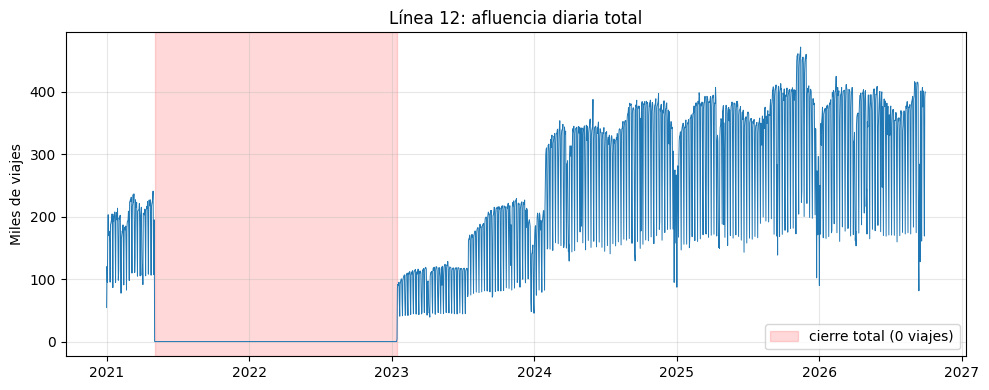

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
s = linea_dia[linea_dia["linea"] == "Línea 12"].set_index("fecha")["afluencia"] / 1e3
ax.plot(s.index, s.values, lw=.7)
ax.axvspan(pd.Timestamp("2021-05-04"), pd.Timestamp("2023-01-14"), alpha=.15, color="red",
           label="cierre total (0 viajes)")
ax.set_title("Línea 12: afluencia diaria total")
ax.set_ylabel("Miles de viajes"); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT_FIG / "D2_ceros_linea12.png", dpi=150); plt.show()

In [17]:
llave_ing = ["fecha", "linea", "tipo_ingreso"]
display(ingresos[ingresos.duplicated(llave_ing, keep=False)]
        .sort_values(llave_ing).head(6))

# 1) Duplicados exactos
n_dup = ingresos.duplicated().sum()
ingresos = ingresos.drop_duplicates()
log_decision("D3", "ingresos", "todas", "duplicado exacto (carga repetida 2022-08-31)",
             n_dup, "eliminar copia", "ninguna: la fila es idéntica")

# 2) Conflicto en la llave: conservar el registro distinto de cero
conflicto = ingresos.duplicated(llave_ing, keep=False)
n_conf = conflicto.sum()
ingresos = (ingresos.sort_values("ingreso", ascending=False, na_position="last")
                    .drop_duplicates(llave_ing, keep="first")
                    .sort_values(llave_ing).reset_index(drop=True))
log_decision("D3", "ingresos", "ingreso", "misma llave con dos valores (14,435 vs 0) dentro del bloque repetido",
             n_conf, "conservar el valor distinto de 0",
             "supone que el 0 viene de la carga repetida; afecta 1 día de 1 línea")

print("Duplicados restantes en la llave:", ingresos.duplicated(llave_ing).sum())

,fecha,tipo_ingreso,linea,ingreso
143892,2022-08-31,QR/Validación,Línea 1,0.0
143904,2022-08-31,QR/Validación,Línea 1,0.0
143903,2022-08-31,QR/Validación,Línea 12,0.0
143915,2022-08-31,QR/Validación,Línea 12,0.0
143893,2022-08-31,QR/Validación,Línea 2,0.0
143905,2022-08-31,QR/Validación,Línea 2,0.0


Duplicados restantes en la llave: 0


In [18]:
# 3) Mecanismo de los faltantes: ¿al azar o concentrados?
ingresos["fecha"] = pd.to_datetime(ingresos["fecha"], format="%Y-%m-%d")
ingresos["falta_ingreso"] = ingresos["ingreso"].isna()
faltantes = ingresos[ingresos["falta_ingreso"]]
display(faltantes.groupby([faltantes["fecha"].dt.year.rename("anio"), "linea", "tipo_ingreso"])["fecha"]
        .agg(registros="count", desde="min", hasta="max"))

# ¿Qué reportó la Línea 12 en los meses vecinos al bloque de 2022?
l12 = ingresos[(ingresos["linea"] == "Línea 12") &
               ingresos["fecha"].between("2021-05-01", "2023-02-28")]
display(l12.groupby(l12["fecha"].dt.to_period("M"))["ingreso"]
        .agg(suma="sum", registros="count", faltantes=lambda x: x.isna().sum()).T)

registros      desde      hasta
anio linea    tipo_ingreso                                  
2012 Línea 12 Boletos              305 2012-01-01 2012-10-31
              Recargas             305 2012-01-01 2012-10-31
              Tarjetas             305 2012-01-01 2012-10-31
2022 Línea 12 QR/Validación         92 2022-03-01 2022-07-31
              Tarjetas              60 2022-03-01 2022-06-29

fecha,2021-05,2021-06,2021-07,2021-08,2021-09,2021-10,2021-11,2021-12,2022-01,2022-02,...,2022-05,2022-06,2022-07,2022-08,2022-09,2022-10,2022-11,2022-12,2023-01,2023-02
suma,2703062.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.535660e+06,1.167442e+07
registros,93.0,90.0,93.0,93.0,90.0,93.0,120.0,124.0,124.0,112.0,...,124.0,61.0,93.0,124.0,120.0,124.0,120.0,124.0,1.240000e+02,1.120000e+02
faltantes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,59.0,31.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00


In [19]:
ingresos["motivo_faltante"] = np.select(
    [ingresos["falta_ingreso"] & (ingresos["fecha"].dt.year == 2012),
     ingresos["falta_ingreso"]],
    ["Línea 12 aún no inaugurada", "Línea 12 cerrada"],
    default="",
)
display(ingresos["motivo_faltante"].value_counts())

log_decision("D3", "ingresos", "ingreso",
             "100 % de los faltantes son de L12: antes de su apertura (2012) o durante su cierre (2022)",
             ingresos["falta_ingreso"].sum(),
             "no imputar; columna motivo_faltante; excluir cierres de L12 en comparaciones por línea",
             "no distingue entre 'no hubo ingreso' y 'no se registró', aunque el contexto indica lo primero")

motivo_faltante
                              158869
Línea 12 aún no inaugurada       915
Línea 12 cerrada                 152
Name: count, dtype: int64

In [20]:
print(ecobici["Genero_Usuario"].value_counts(dropna=False))

# Género: categoría explícita en lugar de imputar con la moda
n_gen = (~ecobici["Genero_Usuario"].isin(["M", "F", "O"])).sum()
ecobici["genero"] = ecobici["Genero_Usuario"].map(
    {"M": "Masculino", "F": "Femenino", "O": "Otro"}).fillna("No especificado")
log_decision("D4", "ecobici", "Genero_Usuario", "'?' y faltante = el usuario no reportó género",
             n_gen, "categoría explícita 'No especificado' (no imputar con la moda)",
             "las proporciones por género se calculan con y sin esta categoría")

print("\nComparación: si imputáramos con la moda ('M'), la proporción masculina pasaría de",
      f"{(ecobici['genero'] == 'Masculino').mean():.1%} a",
      f"{((ecobici['genero'] == 'Masculino') | (ecobici['genero'] == 'No especificado')).mean():.1%}")

Genero_Usuario
M      1029960
F       418009
?        49853
O        27479
NaN          1
Name: count, dtype: int64

Comparación: si imputáramos con la moda ('M'), la proporción masculina pasaría de 67.5% a 70.8%


In [21]:
# Edad: faltantes y extremos
edad = ecobici["Edad_Usuario"]
q1, q3 = edad.quantile([.25, .75]); ric = q3 - q1
lim_sup = q3 + 1.5 * ric
print(f"Faltantes: {edad.isna().sum()} | Q1={q1:.0f}, Q3={q3:.0f}, RIC={ric:.0f}, límite IQR superior={lim_sup:.0f}")
print(f"Por encima del límite IQR: {(edad > lim_sup).sum():,} ({(edad > lim_sup).mean():.2%})")
print(f"Mayores de 80: {(edad > 80).sum()} | distribución de los mayores de 90:",
      edad[edad > 90].value_counts().to_dict())

ecobici["edad_atipica"] = edad > 90
ecobici["rango_edad"] = pd.cut(edad, bins=[15, 24, 34, 44, 54, 64, 100],
                               labels=["16-24", "25-34", "35-44", "45-54", "55-64", "65+"])

log_decision("D4", "ecobici", "Edad_Usuario", "faltantes (79)", edad.isna().sum(),
             "no imputar; quedan fuera solo de los análisis por edad", "pérdida mínima (<0.01 %)")
log_decision("D4", "ecobici", "Edad_Usuario",
             "IQR marca muchos adultos mayores legítimos; >90 años concentrado en 96 y 100",
             ecobici["edad_atipica"].sum(),
             "conservar; bandera edad_atipica; rangos de edad con pd.cut",
             "96 y 100 parecen valores por defecto del registro, pero no es confirmable")

Faltantes: 79 | Q1=28, Q3=40, RIC=12, límite IQR superior=58
Por encima del límite IQR: 43,117 (2.83%)
Mayores de 80: 262 | distribución de los mayores de 90: {96.0: 12, 100.0: 6}


In [22]:
# Duración del viaje (variable derivada)
retiro = pd.to_datetime(ecobici["Fecha_Retiro"] + " " + ecobici["Hora_Retiro"], format="%d/%m/%Y %H:%M:%S")
arribo = pd.to_datetime(ecobici["Fecha_Arribo"] + " " + ecobici["Hora_Arribo"], format="%d/%m/%Y %H:%M:%S")
ecobici["fecha_retiro"] = retiro
ecobici["duracion_min"] = (arribo - retiro).dt.total_seconds() / 60

print(ecobici["duracion_min"].describe(percentiles=[.5, .9, .99, .999]).round(1))
print("Duración negativa:", (ecobici["duracion_min"] < 0).sum(),
      "| > 3 h:", (ecobici["duracion_min"] > 180).sum(),
      "| > 24 h:", (ecobici["duracion_min"] > 1440).sum())
print("Viajes retirados antes de enero 2026:", (retiro < "2026-01-01").sum(),
      "| el más antiguo:", retiro.min())

count    1525302.0
mean          15.7
std          275.8
min            0.2
50%           11.8
90%           30.2
99%           50.0
99.9%        108.4
max       257146.3
Name: duracion_min, dtype: float64
Duración negativa: 0 | > 3 h: 574 | > 24 h: 31
Viajes retirados antes de enero 2026: 105 | el más antiguo: 2025-08-02 23:24:30


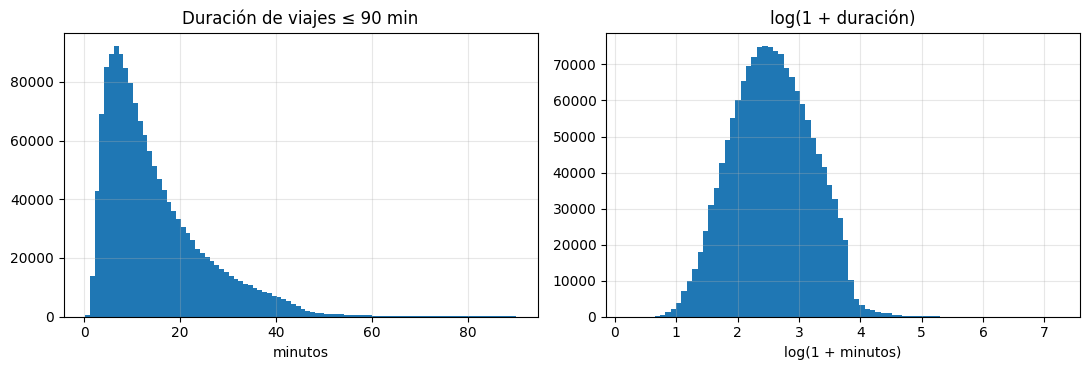

Viajes válidos para el análisis de enero: 1,525,178 de 1,525,302


In [23]:
# Error confirmable vs. atípico plausible
ecobici["duracion_imposible"] = ecobici["duracion_min"] > 1440     # bici fuera más de un día
ecobici["fuera_de_periodo"] = ecobici["fecha_retiro"] < "2026-01-01"

log_decision("D4", "ecobici", "duracion_min", "> 24 h: no es un viaje sino una bici no devuelta o error de cierre",
             ecobici["duracion_imposible"].sum(), "excluir de análisis de duración (bandera duracion_imposible)",
             "algún viaje real muy largo podría quedar fuera")
log_decision("D4", "ecobici", "Fecha_Retiro", "viajes retirados antes de 2026-01-01 que cerraron en enero",
             ecobici["fuera_de_periodo"].sum(), "excluir del análisis de enero (bandera fuera_de_periodo)",
             "el viaje de fin de año que cruza la medianoche del 31 de diciembre queda fuera")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
d = ecobici.loc[~ecobici["duracion_imposible"], "duracion_min"]
axes[0].hist(d[d <= 90], bins=90)
axes[0].set_title("Duración de viajes ≤ 90 min"); axes[0].set_xlabel("minutos")
axes[1].hist(np.log1p(d), bins=80)
axes[1].set_title("log(1 + duración)"); axes[1].set_xlabel("log(1 + minutos)")
for a in axes: a.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT_FIG / "D4_duracion_ecobici.png", dpi=150); plt.show()

print(f"Viajes válidos para el análisis de enero: "
      f"{(~ecobici['duracion_imposible'] & ~ecobici['fuera_de_periodo']).sum():,} de {len(ecobici):,}")

### Un mes con el tipo de pago al revés
Al revisar qué proporción de pasajeros viaja gratis, febrero de 2025 sale muy distinto a los demás meses.

In [24]:
# Sumamos pasajeros por día y tipo de pago
diaria = metro.groupby(["fecha", "tipo_pago"])["afluencia"].sum().unstack()

# Calculamos el porcentaje de gratuidad y su mediana por mes
diaria["porcentaje_gratuidad"] = 100 * diaria["Gratuidad"] / diaria.sum(axis=1)
mensual = diaria.groupby(diaria.index.to_period("M"))["porcentaje_gratuidad"].median()
display(mensual.loc["2024-12":"2025-04"].round(1).to_frame("porcentaje_gratuidad_mediana"))

# Buscamos los días en que más de la mitad de los pasajeros aparece como gratuidad
dias_raros = diaria[diaria["porcentaje_gratuidad"] > 50]
print("Días con más de 50 % de gratuidad:", len(dias_raros))
print("Desde", dias_raros.index.min().date(), "hasta", dias_raros.index.max().date())

,porcentaje_gratuidad_mediana
fecha,
2024-12,12.7
2025-01,13.4
2025-02,87.2
2025-03,12.9
2025-04,13.1


Días con más de 50 % de gratuidad: 28
Desde 2025-02-01 hasta 2025-02-28


### Corrección
Intercambiamos las etiquetas solo en ese mes, sobre una copia `metro_corregido`, y dejamos una columna que indica qué filas se corrigieron. El total de pasajeros no debería cambiar.

In [25]:
# Copiamos la tabla para no modificar la original
metro_corregido = metro.copy()

# Marcamos las filas de febrero 2025 que vamos a corregir
feb_2025 = metro_corregido["fecha"].dt.to_period("M").eq("2025-02")
metro_corregido["tipo_pago_corregido"] = feb_2025 & metro_corregido["tipo_pago"].isin(["Gratuidad", "Prepago"])

# Intercambiamos Gratuidad y Prepago solo en ese mes
metro_corregido.loc[feb_2025, "tipo_pago"] = metro_corregido.loc[feb_2025, "tipo_pago"].replace(
    {"Gratuidad": "Prepago", "Prepago": "Gratuidad"})

# Verificamos que el total no cambie y que no haya duplicados
assert metro_corregido["afluencia"].sum() == metro["afluencia"].sum()
assert metro_corregido.duplicated(["fecha", "linea", "estacion", "tipo_pago"]).sum() == 0

# Revisamos otra vez los días con más de 50 % de gratuidad
revision = metro_corregido.groupby(["fecha", "tipo_pago"])["afluencia"].sum().unstack()
revision["porcentaje_gratuidad"] = 100 * revision["Gratuidad"] / revision.sum(axis=1)
print("Días con más de 50 % de gratuidad después de corregir:", (revision["porcentaje_gratuidad"] > 50).sum())
print("Filas corregidas:", metro_corregido["tipo_pago_corregido"].sum())

# Registramos la decisión
log_decision("D5", "metro", "tipo_pago",
                   "feb-2025: Gratuidad ≈ 87 % y Prepago ≈ 13 % en los 28 días y las 12 líneas (lo normal es al revés)",
                   metro_corregido["tipo_pago_corregido"].sum(),
                   "intercambiar las etiquetas Gratuidad/Prepago en ese mes; bandera tipo_pago_corregido",
                   "supone un error de captura de la fuente; el total de pasajeros no cambia")

# A partir de aquí la tabla del Metro ya lleva la corrección
metro = metro_corregido

Días con más de 50 % de gratuidad después de corregir: 0
Filas corregidas: 10920


In [26]:
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

def agregar_calendario(df, col_fecha="fecha"):
    df["dia_semana"] = pd.Categorical(df[col_fecha].dt.dayofweek.map(dict(enumerate(DIAS))),
                                      categories=DIAS, ordered=True)
    df["tipo_dia"] = np.where(df[col_fecha].dt.dayofweek >= 5, "Fin de semana", "Laboral")
    return df

metrobus["fecha"] = pd.to_datetime(metrobus["fecha"], format="%Y-%m-%d")
metro = agregar_calendario(metro)
metrobus = agregar_calendario(metrobus)
ecobici = agregar_calendario(ecobici, "fecha_retiro")
ecobici["hora_retiro"] = ecobici["fecha_retiro"].dt.hour

# Metrobús: afluencias no enteras (Línea 4, Prepago, enero 2025)
n_frac = (metrobus["afluencia"] % 1 != 0).sum()
metrobus["afluencia"] = metrobus["afluencia"].round().astype("int64")
log_decision("T", "metrobus", "afluencia", "57 conteos con decimales (L4, Prepago, ene-2025), probablemente estimados",
             n_frac, "redondear al entero", "el valor original pudo ser una estimación de la fuente")

# Afluencia histórica: texto con comas -> número
for col in ["afluencia_tarjeta", "afluencia_boleto", "afluencia_total_preliminar"]:
    historico[col] = pd.to_numeric(historico[col].astype(str).str.replace(",", "", regex=False),
                                   errors="coerce")
historico["fecha"] = pd.to_datetime(historico["fecha"], format="%Y-%m-%d")
log_decision("T", "historico", "afluencia_*", "números guardados como texto con comas de miles",
             len(historico), "convertir a numérico",
             "tarjeta/boleto faltan por estructura en organismos que no los distinguen; no se imputan")

display(historico.dtypes.to_frame("tipo"))

,tipo
id,int64
organismo,object
linea_servicio,object
dia,object
fecha,datetime64[ns]
afluencia_tarjeta,float64
afluencia_boleto,float64
afluencia_total_preliminar,float64


In [27]:
bitacora = pd.DataFrame(registro)
display(bitacora)

bitacora.to_csv(OUT_DATA / "bitacora_limpieza.csv", index=False)
metro.to_csv(OUT_DATA / "metro_limpio.csv.gz", index=False, compression="gzip")
metrobus.to_csv(OUT_DATA / "metrobus_limpio.csv", index=False)
ingresos.to_csv(OUT_DATA / "ingresos_limpio.csv.gz", index=False, compression="gzip")
historico.to_csv(OUT_DATA / "afluencia_historica_limpia.csv", index=False)
cols_eco = ["genero", "Edad_Usuario", "rango_edad", "edad_atipica", "Ciclo_Estacion_Retiro",
            "Ciclo_EstacionArribo", "fecha_retiro", "hora_retiro", "dia_semana", "tipo_dia",
            "duracion_min", "duracion_imposible", "fuera_de_periodo"]
ecobici[cols_eco].to_csv(OUT_DATA / "ecobici_2026_01_limpio.csv.gz", index=False, compression="gzip")

for f in sorted(OUT_DATA.iterdir()):
    print(f"{f.name:40s} {f.stat().st_size / 1e6:6.1f} MB")

,paso,tabla,variable,criterio,filas_afectadas,accion,limitacion
0,D1,metro,linea,mojibake y 'Linea' sin acento según el periodo,1227915,estandarizar a 'Línea X',ninguna: es la misma línea
1,D1,metro,estacion,mojibake y variantes de acentos/mayúsculas,396801,reparar codificación y unificar a la escritura...,la unificación supone que nombres iguales sin ...
2,D1,metrobus,linea,tres escrituras distintas según el periodo,6398,estandarizar a 'Línea X',ninguna
3,D1,ingresos,tipo_ingreso,'QR/Validador' renombrado por la fuente en dic...,2916,unificar en 'QR/Validación',supone que el cambio fue solo de nombre y no d...
4,D2,metro,afluencia,estación-día con afluencia total 0 = sin servi...,89292,conservar filas y crear bandera en_servicio; p...,una estación abierta con 0 accesos reales serí...
5,D3,ingresos,todas,duplicado exacto (carga repetida 2022-08-31),11,eliminar copia,ninguna: la fila es idéntica
6,D3,ingresos,ingreso,"misma llave con dos valores (14,435 vs 0) dent...",2,conservar el valor distinto de 0,supone que el 0 viene de la carga repetida; af...
7,D3,ingresos,ingreso,100 % de los faltantes son de L12: antes de su...,1067,no imputar; columna motivo_faltante; excluir c...,no distingue entre 'no hubo ingreso' y 'no se ...
8,D4,ecobici,Genero_Usuario,'?' y faltante = el usuario no reportó género,49854,categoría explícita 'No especificado' (no impu...,las proporciones por género se calculan con y ...
9,D4,ecobici,Edad_Usuario,faltantes (79),79,no imputar; quedan fuera solo de los análisis ...,pérdida mínima (<0.01 %)


afluencia_historica_limpia.csv              1.0 MB
bitacora_limpieza.csv                       0.0 MB
ecobici_2026_01_limpio.csv.gz              20.0 MB
ingresos_limpio.csv.gz                      0.9 MB
metro_limpio.csv.gz                         9.3 MB
metrobus_limpio.csv                         1.9 MB


## 3.2 Manipulación de los datos (transformación para el análisis)

Tomamos los datos limpios de la sección anterior y los **reorganizamos**
para responder nuestras preguntas, sin modificar los archivos originales.

Cada base cuenta los viajes de forma distinta: Metro por **estación y día**, Metrobús por **línea y día**, Ecobici por **viaje** individual. Compararlas así sería como comparar lo que pasa en una estación contra lo que pasa en una línea. Por eso primero las **sumamos a una misma medida** (por ejemplo, pasajeros por línea por día) y después las juntamos.

El resultado son tablas listas para la parte de estadística y de visualización.

### Contenido por tabla
Revisamos el contenido y el periodo de cada tabla limpia.

In [28]:
# Anotamos qué representa cada renglón y cuál es su columna de fecha
tablas = {"metro": (metro, "fecha", "estación × día × tipo de pago"),
          "metrobus": (metrobus, "fecha", "línea × día × tipo de pago"),
          "ingresos": (ingresos, "fecha", "línea × día × tipo de ingreso"),
          "historico": (historico, "fecha", "organismo/línea × día"),
          "ecobici": (ecobici, "fecha_retiro", "un viaje")}

# Armamos el inventario: filas, columnas y periodo de cada tabla
inventario = pd.DataFrame([
    {"tabla": nombre, "cada_renglon_es": unidad, "filas": len(tabla), "columnas": tabla.shape[1],
     "desde": tabla[columna_fecha].min().date(), "hasta": tabla[columna_fecha].max().date()}
    for nombre, (tabla, columna_fecha, unidad) in tablas.items()
])
display(inventario)

,tabla,cada_renglon_es,filas,columnas,desde,hasta
0,metro,estación × día × tipo de pago,1227915,11,2021-01-01,2026-09-30
1,metrobus,línea × día × tipo de pago,29386,8,2021-01-01,2026-09-30
2,ingresos,línea × día × tipo de ingreso,159936,6,2012-01-01,2023-07-31
3,historico,organismo/línea × día,18714,8,2020-03-01,2021-07-02
4,ecobici,un viaje,1525302,19,2025-08-02,2026-01-31


### Transformación del sistema del Metro
Cada renglón de Metro es una estación en un día. Para comparar líneas (y después con Metrobús e ingresos), sumamos todas las estaciones de cada línea. Los tipos de pago pasan a ser columnas.

In [29]:
# Sumamos pasajeros por línea, día y tipo de pago; cada tipo de pago queda como columna
pasajeros = (metro_corregido.groupby(["fecha", "linea", "tipo_pago"])["afluencia"].sum()
                            .unstack("tipo_pago")
                            .reset_index())
pasajeros.columns.name = None
pasajeros = pasajeros.rename(columns={"Boleto": "boleto", "Prepago": "prepago", "Gratuidad": "gratuidad"})

# Contamos cuántas estaciones tiene cada línea y cuántas abrieron ese día
estaciones = (metro_corregido.drop_duplicates(["fecha", "linea", "estacion"])
                             .groupby(["fecha", "linea"])
                             .agg(estaciones=("estacion", "size"),
                                  estaciones_abiertas=("en_servicio", "sum"))
                             .reset_index())

# Unimos ambas tablas y calculamos el total de pasajeros
metro_linea_dia = pasajeros.merge(estaciones, on=["fecha", "linea"], how="left", validate="one_to_one")
metro_linea_dia["total"] = metro_linea_dia[["boleto", "prepago", "gratuidad"]].sum(axis=1)

#### Conservación de pasajeros
El total de pasajeros antes y después tiene que ser idéntico.

In [30]:
# Verificamos que no haya duplicados ni se pierdan pasajeros
assert metro_linea_dia[["fecha", "linea"]].duplicated().sum() == 0
assert metro_linea_dia["total"].sum() == metro_corregido["afluencia"].sum()
assert len(metro_linea_dia) == metro_corregido["fecha"].nunique() * metro_corregido["linea"].nunique()

print("Filas antes:", len(metro_corregido), "- después:", len(metro_linea_dia))
print("Pasajeros antes:", metro_corregido["afluencia"].sum(), "- después:", metro_linea_dia["total"].sum())

# Registramos la decisión
log_decision("M1", "metro", "afluencia", "estación × día × tipo de pago → línea × día",
                   len(metro_corregido), "sumar estaciones; tipos de pago como columnas",
                   "se pierde el detalle por estación (sigue disponible en metro_corregido)")

Filas antes: 1227915 - después: 25188
Pasajeros antes: 6298847633 - después: 6298847633


#### Variables nuevas
- `linea_abierta`: la línea tuvo pasajeros ese día (si suma 0, estuvo cerrada).
- `cierre_parcial`: la línea operó, pero con alguna estación cerrada.
- `porcentaje_boleto`, `porcentaje_prepago`, `porcentaje_gratuidad`: qué porcentaje de los pasajeros pagó de cada forma (de 0 a 100). Si la línea estuvo cerrada, se deja vacío.
- `mes`, `dia_semana`, `tipo_dia`: para comparar por calendario.

In [31]:
# Marcamos si la línea abrió y si tuvo alguna estación cerrada
metro_linea_dia["linea_abierta"] = metro_linea_dia["total"].gt(0)
metro_linea_dia["cierre_parcial"] = (metro_linea_dia["linea_abierta"]
                                     & metro_linea_dia["estaciones_abiertas"].lt(metro_linea_dia["estaciones"]))

# Calculamos el porcentaje de cada tipo de pago (vacío si la línea estuvo cerrada)
for tipo in ["boleto", "prepago", "gratuidad"]:
    metro_linea_dia[f"porcentaje_{tipo}"] = np.where(metro_linea_dia["total"].gt(0),
                                                     100 * metro_linea_dia[tipo] / metro_linea_dia["total"], np.nan)

# Agregamos mes, día de la semana y tipo de día
metro_linea_dia["mes"] = metro_linea_dia["fecha"].dt.to_period("M").astype("string")
metro_linea_dia = agregar_calendario(metro_linea_dia)
display(metro_linea_dia.head())

,fecha,linea,boleto,gratuidad,prepago,estaciones,estaciones_abiertas,total,linea_abierta,cierre_parcial,porcentaje_boleto,porcentaje_prepago,porcentaje_gratuidad,mes,dia_semana,tipo_dia
0,2021-01-01,Línea 1,69381,13533,46664,20,20,129578,True,False,53.543811,36.012286,10.443903,2021-01,Viernes,Laboral
1,2021-01-01,Línea 12,0,15390,39226,20,20,54616,True,False,0.000000,71.821444,28.178556,2021-01,Viernes,Laboral
2,2021-01-01,Línea 2,39314,13143,39425,24,24,91882,True,False,42.787488,42.908295,14.304216,2021-01,Viernes,Laboral
3,2021-01-01,Línea 3,41833,11587,43300,21,21,96720,True,False,43.251654,44.768404,11.979942,2021-01,Viernes,Laboral
4,2021-01-01,Línea 4,7168,2919,4199,10,10,14286,True,False,50.174997,29.392412,20.432591,2021-01,Viernes,Laboral


#### Resumen por línea
La mediana de pasajeros se calcula solo con los días en que la línea estuvo abierta,
para no mezclar cierres con días normales (decisión D2 de la limpieza).

In [32]:
# Resumimos cada línea en días, cierres y gratuidad
resumen_lineas = (metro_linea_dia.groupby("linea")
                                 .agg(dias=("fecha", "size"),
                                      dias_cerrada=("linea_abierta", lambda s: int((~s).sum())),
                                      dias_cierre_parcial=("cierre_parcial", "sum"),
                                      mediana_porcentaje_gratuidad=("porcentaje_gratuidad", "median")))

# Calculamos la mediana de pasajeros usando solo los días en que la línea abrió
dias_abiertos = metro_linea_dia.loc[metro_linea_dia["linea_abierta"]]
resumen_lineas["mediana_pasajeros_abierta"] = dias_abiertos.groupby("linea")["total"].median()
display(resumen_lineas.sort_values("mediana_pasajeros_abierta", ascending=False).round(1))

,dias,dias_cerrada,dias_cierre_parcial,mediana_porcentaje_gratuidad,mediana_pasajeros_abierta
linea,,,,,
Línea 2,2099,30,293,11.9,556664.0
Línea 3,2099,23,39,12.0,472032.0
Línea B,2099,0,2,12.8,346372.0
Línea 8,2099,0,1,13.1,336828.0
Línea 12,2099,621,382,11.7,255976.5
Línea 1,2099,16,1293,17.3,250024.0
Línea 9,2099,0,279,9.5,242935.0
Línea 7,2099,0,141,10.1,216958.0
Línea A,2099,0,0,11.3,206580.0


### Metrobús por línea y día
Metrobús ya viene por línea y día, así que solo pasamos los tipos de pago a columnas.
Metrobús no registra Boleto a diferencia del metro.

In [33]:
# Pasamos los tipos de pago a columnas
metrobus_linea_dia = (metrobus.pivot_table(index=["fecha", "linea"], columns="tipo_pago",
                                           values="afluencia", aggfunc="sum")
                              .reset_index())
metrobus_linea_dia.columns.name = None
metrobus_linea_dia = metrobus_linea_dia.rename(columns={"Prepago": "prepago", "Gratuidad": "gratuidad"})

# Calculamos el total y el porcentaje de gratuidad
metrobus_linea_dia["total"] = metrobus_linea_dia["prepago"] + metrobus_linea_dia["gratuidad"]
metrobus_linea_dia["porcentaje_gratuidad"] = 100 * metrobus_linea_dia["gratuidad"] / metrobus_linea_dia["total"]

# Verificamos que no haya duplicados ni se pierdan pasajeros
assert metrobus_linea_dia[["fecha", "linea"]].duplicated().sum() == 0
assert metrobus_linea_dia["total"].sum() == metrobus["afluencia"].sum()
print("Filas antes:", len(metrobus), "- después:", len(metrobus_linea_dia))
print("Celdas vacías:", metrobus_linea_dia.isna().sum().sum())

Filas antes: 29386 - después: 14693
Celdas vacías: 0


#### Metro y Metrobús en una misma tabla
Sumamos todas las líneas de cada sistema por día. Así cada renglón es un sistema en un día
y ambos quedan en la misma medida para compararlos.

In [34]:
# Sumamos todas las líneas de cada sistema por día y juntamos ambos sistemas
sistemas_dia = pd.concat([
    metro_linea_dia.groupby("fecha")[["prepago", "gratuidad", "boleto"]].sum().assign(sistema="Metro"),
    metrobus_linea_dia.groupby("fecha")[["prepago", "gratuidad"]].sum().assign(boleto=0, sistema="Metrobús"),
]).reset_index()

# Calculamos el total, el porcentaje de gratuidad y el calendario
sistemas_dia["total"] = sistemas_dia[["prepago", "gratuidad", "boleto"]].sum(axis=1)
sistemas_dia["porcentaje_gratuidad"] = 100 * sistemas_dia["gratuidad"] / sistemas_dia["total"]
sistemas_dia["mes"] = sistemas_dia["fecha"].dt.to_period("M").astype("string")
sistemas_dia = agregar_calendario(sistemas_dia)

# Verificamos que cada sistema aparezca una sola vez por día
assert sistemas_dia[["fecha", "sistema"]].duplicated().sum() == 0

# Comparamos días laborales contra fines de semana
display(sistemas_dia.groupby(["sistema", "tipo_dia"])
                    .agg(dias=("fecha", "size"), mediana_pasajeros=("total", "median"),
                         mediana_porcentaje_gratuidad=("porcentaje_gratuidad", "median")).round(1))

# Registramos la decisión
log_decision("M2", "metro + metrobus", "afluencia", "unir ambos sistemas a sistema × día",
                   len(sistemas_dia), "sumar líneas; boleto = 0 en Metrobús porque no existe",
                   "Metrobús no distingue boleto; comparar tipo de pago solo con prepago y gratuidad")

dias  mediana_pasajeros  mediana_porcentaje_gratuidad
sistema  tipo_dia                                                            
Metro    Fin de semana   600          2076753.5                          11.9
         Laboral        1499          3455312.0                          12.4
Metrobús Fin de semana   600           833927.5                           6.5
         Laboral        1499          1542818.0                           6.2

### Ingresos y pasajeros del Metro (2021–2023)
Los ingresos solo existen hasta julio de 2023 y los pasajeros desde enero de 2021, así que trabajamos
en el periodo que comparten. Usamos **meses** y no días. Una recarga de tarjeta se compra un día
y se gasta en muchos viajes después, por lo que día con día los ingresos y los viajes no coinciden.

In [35]:
fecha_inicio, fecha_fin = "2021-01-01", "2023-07-31"

# Filtramos los ingresos al periodo que comparten ambas bases
ingresos_periodo = ingresos.loc[ingresos["fecha"].between(fecha_inicio, fecha_fin)].copy()
ingresos_periodo["mes"] = ingresos_periodo["fecha"].dt.to_period("M").astype("string")

# Sumamos los ingresos por línea y mes; cada tipo de ingreso queda como columna
ingresos_mes = (ingresos_periodo.pivot_table(index=["linea", "mes"], columns="tipo_ingreso",
                                             values="ingreso", aggfunc="sum", fill_value=0)
                                .reset_index())
ingresos_mes.columns.name = None
ingresos_mes = ingresos_mes.rename(columns={"Boletos": "ingreso_boletos", "Recargas": "ingreso_recargas",
                                            "Tarjetas": "ingreso_tarjetas", "QR/Validación": "ingreso_qr"})
ingresos_mes["ingreso_total"] = ingresos_mes[["ingreso_boletos", "ingreso_recargas",
                                              "ingreso_tarjetas", "ingreso_qr"]].sum(axis=1)

# Sumamos los pasajeros por línea y mes en el mismo periodo
pasajeros_mes = (metro_linea_dia.loc[metro_linea_dia["fecha"].between(fecha_inicio, fecha_fin)]
                                .groupby(["linea", "mes"])
                                .agg(pasajeros=("total", "sum"), boleto=("boleto", "sum"),
                                     prepago=("prepago", "sum"), gratuidad=("gratuidad", "sum"),
                                     dias_abierta=("linea_abierta", "sum"))
                                .reset_index())
pasajeros_mes["pagantes"] = pasajeros_mes["boleto"] + pasajeros_mes["prepago"]

#### Unión segura
Ambas tablas tienen ahora la misma medida (línea × mes), así que cada renglón debe encontrar
exactamente una pareja. `indicator` nos muestra si algún renglón se quedó sin pareja

In [36]:
# Unimos ambas tablas y revisamos si algún renglón quedó sin pareja
ingresos_pasajeros = pasajeros_mes.merge(ingresos_mes, on=["linea", "mes"], how="outer",
                                         validate="one_to_one", indicator=True)
display(ingresos_pasajeros["_merge"].value_counts().to_frame("filas"))
assert ingresos_pasajeros["_merge"].eq("both").all()

# Quitamos la columna de revisión
ingresos_pasajeros = ingresos_pasajeros.drop(columns="_merge")

,filas
_merge,
both,372
left_only,0
right_only,0


#### Ingreso por pasajero que paga
Dividimos el ingreso entre los pasajeros que pagan (Boleto + Prepago; la gratuidad no genera ingreso).
Si las bases cuadran, el resultado debe estar cerca de la tarifa del Metro: **$5**.
Los meses en que la Línea 12 estuvo cerrada quedan vacíos.

In [37]:
# Marcamos los meses en que la línea estuvo cerrada
ingresos_pasajeros["linea_cerrada"] = ingresos_pasajeros["dias_abierta"].eq(0)

# Calculamos el ingreso por pasajero que paga (vacío si no hubo pagantes)
ingresos_pasajeros["ingreso_por_pagante"] = np.where(ingresos_pasajeros["pagantes"].gt(0),
                                                     ingresos_pasajeros["ingreso_total"] / ingresos_pasajeros["pagantes"],
                                                     np.nan)
print("Meses-línea cerrados:", ingresos_pasajeros["linea_cerrada"].sum())
display(ingresos_pasajeros.groupby("linea")["ingreso_por_pagante"]
                          .describe()[["count", "min", "50%", "max"]].round(2))

# Sumamos todo el Metro por mes (tabla principal de la pregunta 3)
metro_ingresos_mes = (ingresos_pasajeros.groupby("mes")[["pasajeros", "pagantes", "gratuidad",
                                                         "ingreso_boletos", "ingreso_recargas", "ingreso_tarjetas",
                                                         "ingreso_qr", "ingreso_total"]]
                                        .sum().reset_index())
metro_ingresos_mes["ingreso_por_pagante"] = metro_ingresos_mes["ingreso_total"] / metro_ingresos_mes["pagantes"]
display(metro_ingresos_mes.head())

# Registramos la decisión
log_decision("M3", "ingresos + metro", "ingreso", "unir ingresos y pasajeros por línea × mes (ene-2021 a jul-2023)",
                   len(ingresos_pasajeros), "agregar por mes; ingreso_por_pagante = ingreso / (boleto + prepago)",
                   "la recarga se vende en una línea y puede usarse en otra: comparar por línea con cautela")

Meses-línea cerrados: 19


,count,min,50%,max
linea,,,,
Línea 1,31.0,4.56,5.22,5.61
Línea 12,12.0,5.44,5.80,6.67
Línea 2,31.0,4.97,5.40,5.74
Línea 3,31.0,4.84,5.31,5.73
Línea 4,31.0,3.40,5.16,5.66
Línea 5,31.0,4.54,4.82,5.30
Línea 6,31.0,3.60,4.29,4.49
Línea 7,31.0,5.30,5.86,6.13
Línea 8,31.0,4.52,4.98,5.28


,mes,pasajeros,pagantes,gratuidad,ingreso_boletos,ingreso_recargas,ingreso_tarjetas,ingreso_qr,ingreso_total,ingreso_por_pagante
0,2021-01,41033642,36287874,4745768,47454875.0,1.440367e+08,1484355.0,0.0,1.929760e+08,5.317918
1,2021-02,50436321,46141886,4294435,64846325.0,1.786339e+08,1705425.0,0.0,2.451857e+08,5.313733
2,2021-03,65449779,60433657,5016122,85644965.0,2.264336e+08,2241675.0,0.0,3.143203e+08,5.201080
3,2021-04,62577359,57661064,4916295,82950270.0,2.087748e+08,2150445.0,0.0,2.938756e+08,5.096603
4,2021-05,62689975,56985969,5704006,94883350.0,1.894670e+08,1648830.0,0.0,2.859992e+08,5.018766


### Ecobici: de viaje individual a día y hora
Cada renglón de Ecobici es un viaje. Primero quitamos los viajes marcados en la limpieza
(más de 24 h o iniciados antes de enero) y después contamos cuántos viajes hubo por
día, hora, género y rango de eda

In [38]:
# Filtramos los viajes válidos según las banderas de la limpieza
validos = ~ecobici["duracion_imposible"] & ~ecobici["fuera_de_periodo"]
ecobici_validos = ecobici.loc[validos].copy()
print("Viajes válidos:", len(ecobici_validos), "de", len(ecobici))
print("Viajes excluidos:", (~validos).sum())

# Separamos el día y conservamos a quienes no tienen edad registrada
ecobici_validos["fecha"] = ecobici_validos["fecha_retiro"].dt.normalize()
ecobici_validos["rango_edad"] = ecobici_validos["rango_edad"].astype("string").fillna("Sin edad")

# Contamos viajes y duración mediana por día, hora, género y edad
ecobici_hora = (ecobici_validos.groupby(["fecha", "hora_retiro", "genero", "rango_edad"])
                               .agg(viajes=("duracion_min", "size"),
                                    duracion_mediana=("duracion_min", "median"))
                               .reset_index())

# Agregamos día de la semana y tipo de día
ecobici_hora = agregar_calendario(ecobici_hora)

# Verificamos que no se pierdan viajes ni haya duplicados
assert ecobici_hora["viajes"].sum() == len(ecobici_validos)
assert ecobici_hora.duplicated(["fecha", "hora_retiro", "genero", "rango_edad"]).sum() == 0
print("Renglones resultantes:", len(ecobici_hora))

# Registramos la decisión
log_decision("M4", "ecobici", "viajes", "viaje → día × hora × género × rango de edad",
                   len(ecobici_validos), "excluir banderas D4 y contar viajes; mediana de duración por grupo",
                   "se pierde el detalle por estación; enero 2026 no permite ver estacionalidad")

Viajes válidos: 1525178 de 1525302
Viajes excluidos: 124
Renglones resultantes: 12995


#### Viajes promedio por hora
Dividimos entre el número de días de cada tipo (22 laborales y 9 de fin de semana),
porque si no, los días laborales parecerían más usados solo por ser más.

In [39]:
# Sumamos los viajes por hora y tipo de día
viajes_por_hora = ecobici_hora.pivot_table(index="hora_retiro", columns="tipo_dia", values="viajes", aggfunc="sum")

# Dividimos entre el número de días de cada tipo para obtener el promedio diario
viajes_por_hora = viajes_por_hora / ecobici_hora.groupby("tipo_dia")["fecha"].nunique()
display(viajes_por_hora.round(0).astype(int).T)

hora_retiro,0,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
tipo_dia,,,,,,,,,,,,,,,,,,,,
Fin de semana,262,120,362,777,1369,1984,2526,2913,3087,3104,2862,2644,2332,2138,1943,1610,1337,1088,825,539
Laboral,153,461,1552,3234,4349,3180,2373,2248,2408,3027,3777,3918,3829,4735,5289,4041,2813,2052,1318,733


#### Los tres sistemas en enero 2026
Enero 2026 es el único mes en que tenemos Metro, Metrobús y Ecobici al mismo tiempo.
Juntamos sus viajes por día en una sola tabla.

In [40]:
# Contamos los viajes de Ecobici por día
ecobici_dia = ecobici_validos.groupby("fecha").size().rename("total").reset_index().assign(sistema="Ecobici")

# Juntamos los tres sistemas en enero 2026
enero_2026 = pd.concat([sistemas_dia.loc[sistemas_dia["mes"].eq("2026-01"), ["fecha", "sistema", "total"]],
                        ecobici_dia], ignore_index=True)
enero_2026 = agregar_calendario(enero_2026)
assert enero_2026[["fecha", "sistema"]].duplicated().sum() == 0

# Comparamos la mediana de fin de semana contra la de día laboral
comparacion = enero_2026.pivot_table(index="sistema", columns="tipo_dia", values="total", aggfunc="median")
comparacion["finde_entre_laboral"] = comparacion["Fin de semana"] / comparacion["Laboral"]
display(comparacion.round(2))

tipo_dia,Fin de semana,Laboral,finde_entre_laboral
sistema,,,
Ecobici,34438.0,59092.5,0.58
Metro,2815078.0,3731433.0,0.75
Metrobús,996497.0,1546643.5,0.64


### Guardar resultados
Guardamos las tablas en `data/analitica/` con nombres que empiezan con `tabla_`, para distinguirlas
de los datos limpios. La bitácora va en un archivo aparte, así no se modifica la de la limpieza.

In [41]:
# Creamos la carpeta donde guardamos las tablas analíticas
carpeta_salida = ROOT / "data" / "analitica"
carpeta_salida.mkdir(parents=True, exist_ok=True)


# Definimos qué tabla va en cada archivo y para qué pregunta sirve
salidas = {
    "tabla_metro_linea_dia.csv":              (metro_linea_dia,    "línea del Metro × día",              "P1"),
    "tabla_metrobus_linea_dia.csv":           (metrobus_linea_dia, "línea del Metrobús × día",           "P1"),
    "tabla_sistemas_dia.csv":                 (sistemas_dia,       "sistema (Metro/Metrobús) × día",     "P1"),
    "tabla_ingresos_pasajeros_linea_mes.csv": (ingresos_pasajeros, "línea del Metro × mes (2021–2023)",  "P3"),
    "tabla_metro_ingresos_mes.csv":           (metro_ingresos_mes, "todo el Metro × mes (2021–2023)",    "P3"),
    "tabla_ecobici_dia_hora.csv":             (ecobici_hora,       "día × hora × género × edad",         "P2"),
    "tabla_enero_2026_sistemas.csv":          (enero_2026,         "sistema (los tres) × día, ene-2026", "P2"),
}

# Guardamos cada tabla y anotamos su tamaño
resumen_salidas = []
for archivo, (tabla, unidad, pregunta) in salidas.items():
    tabla.to_csv(carpeta_salida / archivo, index=False)
    resumen_salidas.append({"archivo": archivo, "cada_renglon_es": unidad, "pregunta": pregunta,
                            "filas": len(tabla), "columnas": tabla.shape[1]})
display(pd.DataFrame(resumen_salidas))

,archivo,cada_renglon_es,pregunta,filas,columnas
0,tabla_metro_linea_dia.csv,línea del Metro × día,P1,25188,16
1,tabla_metrobus_linea_dia.csv,línea del Metrobús × día,P1,14693,6
2,tabla_sistemas_dia.csv,sistema (Metro/Metrobús) × día,P1,4198,10
3,tabla_ingresos_pasajeros_linea_mes.csv,línea del Metro × mes (2021–2023),P3,372,15
4,tabla_metro_ingresos_mes.csv,todo el Metro × mes (2021–2023),P3,31,10
5,tabla_ecobici_dia_hora.csv,día × hora × género × edad,P2,12995,8
6,tabla_enero_2026_sistemas.csv,"sistema (los tres) × día, ene-2026",P2,93,5


#### Bitácora completa
Unimos las decisiones de limpieza (D1–D5, T) con las de manipulación (M1–M4) para tener todo el recorrido.

In [42]:
# Guardamos la bitácora de manipulación en un archivo aparte
bitacora_completa = pd.DataFrame(registro)
bitacora_manipulacion = bitacora_completa[bitacora_completa["paso"].str.startswith("M")]
bitacora_manipulacion.to_csv(carpeta_salida / "bitacora_manipulacion.csv", index=False)

# Mostramos la bitácora completa: limpieza y manipulación
display(bitacora_completa[["paso", "tabla", "variable", "accion"]])

,paso,tabla,variable,accion
0,D1,metro,linea,estandarizar a 'Línea X'
1,D1,metro,estacion,reparar codificación y unificar a la escritura...
2,D1,metrobus,linea,estandarizar a 'Línea X'
3,D1,ingresos,tipo_ingreso,unificar en 'QR/Validación'
4,D2,metro,afluencia,conservar filas y crear bandera en_servicio; p...
5,D3,ingresos,todas,eliminar copia
6,D3,ingresos,ingreso,conservar el valor distinto de 0
7,D3,ingresos,ingreso,no imputar; columna motivo_faltante; excluir c...
8,D4,ecobici,Genero_Usuario,categoría explícita 'No especificado' (no impu...
9,D4,ecobici,Edad_Usuario,no imputar; quedan fuera solo de los análisis ...


#### Resumen

Cátalogo de archivos creados:

| Tema | Archivo | Cada renglón es |
|:--|:--|:--|
| Tipo de pago | tabla_metro_linea_dia.csv | una línea del Metro en un día |
| Tipo de pago | tabla_metrobus_linea_dia.csv | una línea del Metrobús en un día |
| Tipo de pago | tabla_sistemas_dia.csv | un sistema (Metro o Metrobús) en un día |
| Ecobici | tabla_ecobici_dia_hora.csv | un grupo de género y edad en una hora de un día |
| Ecobici | tabla_enero_2026_sistemas.csv | un sistema (los tres) en un día de enero 2026 |
| Ingresos | tabla_metro_ingresos_mes.csv | todo el Metro en un mes (2021–2023) |
| Ingresos | tabla_ingresos_pasajeros_linea_mes.csv | una línea del Metro en un mes (2021–2023) |

Cada tabla conserva el total de pasajeros o viajes de su fuente (lo verificamos con `assert`).

# 4. Visualización de datos

Este módulo transforma los datos disponibles en **preguntas de investigación descriptivas**. Cada visualización responde una pregunta concreta y se acompaña de una interpretación basada en los datos, su relevancia y sus limitaciones.

**Fuentes**
- `Afluencia Diaria del Metro (Desglosada).csv` y `Afluencia Diaria del Metrobús (Desglosada).csv` (ya limpias)
- `Afluencia Preliminar en Transporte Publico (histórico).csv` (ya limpia)
- `Ingresos del Sistema de Transporte Colectivo Metro.csv` (ya limpia)
- `Viajes diarios del sistema Ecobici.csv`: evolución diaria por género (2010–2024).
- `Viajes mensuales desglosados del sistema Ecobici.csv`: viajes por hora, género y rango de edad (2010–2024).
- `Viajes Ecobico 2026-01.csv`: viajes individuales de enero de 2026 (ya limpios).
- `Ubicación de estaciones ecobici.csv`: ubicación, alcaldía, tipo y capacidad de estaciones.

### Objetivos

1. Identificar tendencias de largo plazo y estacionalidad.
2. Describir diferencias por día, hora, género y edad.
3. Analizar distribución y capacidad de infraestructura.
4. Detectar estaciones, rutas y desequilibrios operativos en enero de 2026.
5. Analizar duración sin dejar que registros temporalmente anómalos distorsionen las métricas.

Preparación de los datos

In [43]:
import matplotlib.ticker as mtick
import matplotlib.ticker as mticker
from IPython.display import Markdown
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)

COL = {'verde':'#2A9D8F','azul':'#457B9D','amarillo':'#E9C46A','naranja':'#F4A261','rojo':'#E76F51','morado':'#7B6DCC'}

# Las tablas metro, metrobus, historico e ingresos ya están limpias (sección de limpieza).
# Solo agregamos el mes como fecha para las series mensuales.
for df in (metro, metrobus, historico, ingresos):
    df['mes_calc'] = df['fecha'].dt.to_period('M').dt.to_timestamp()

print(f"Cobertura Metro: {metro['fecha'].min().date()} a {metro['fecha'].max().date()}")

Cobertura Metro: 2021-01-01 a 2026-09-30


## 4.1 Metro, Metrobús e ingresos

### Líneas con mayor afluencia diaria

#### Pregunta 1
**¿Qué líneas concentran la mayor afluencia diaria promedio en cada sistema?**

Se utiliza el **promedio diario por línea** en vez del acumulado total. Así se reduce el sesgo que introducirían diferencias en la cantidad de días disponibles por línea o año.


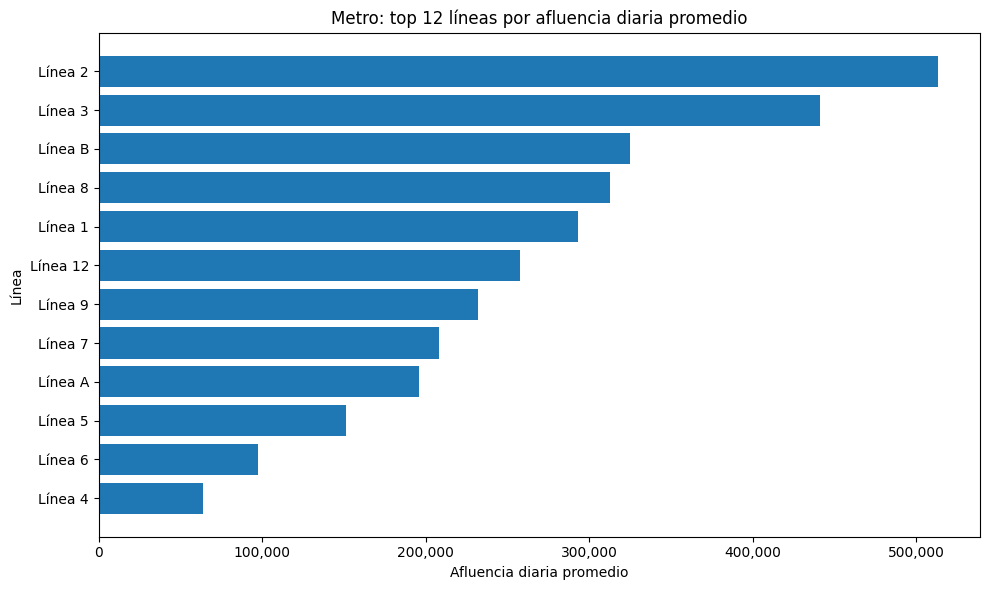

**Interpretación — Metro.** **Línea 2** registra la mayor afluencia diaria promedio: **513,397** pasajeros.  
**Relevancia.** Identifica corredores estratégicos por volumen de demanda.  
**Limitación.** El ranking no incorpora capacidad, longitud, número de estaciones ni kilómetros operados; por tanto, no mide eficiencia ni saturación.

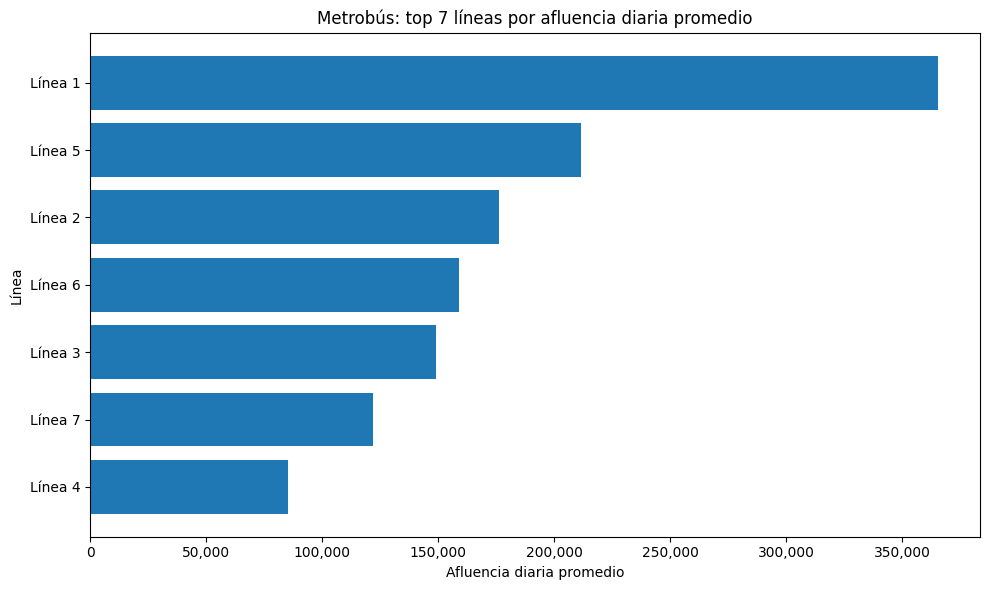

**Interpretación — Metrobús.** **Línea 1** registra la mayor afluencia diaria promedio: **365,323** pasajeros.  
**Relevancia.** Identifica corredores estratégicos por volumen de demanda.  
**Limitación.** El ranking no incorpora capacidad, longitud, número de estaciones ni kilómetros operados; por tanto, no mide eficiencia ni saturación.

In [44]:
def ranking_lineas(df, sistema, top=12):
    diario = df.groupby(['fecha', 'linea'], as_index=False)['afluencia'].sum()
    # Solo días con servicio (decisión D2): un cierre no es baja demanda
    diario = diario[diario['afluencia'] > 0]
    ranking = (diario.groupby('linea')['afluencia']
                     .agg(promedio='mean', mediana='median', dias='count')
                     .sort_values('promedio', ascending=True)
                     .tail(top))

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(ranking.index, ranking['promedio'])
    ax.set_title(f'{sistema}: top {min(top, len(ranking))} líneas por afluencia diaria promedio')
    ax.set_xlabel('Afluencia diaria promedio')
    ax.set_ylabel('Línea')
    ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
    plt.tight_layout()
    plt.show()

    lider = ranking['promedio'].idxmax()
    display(Markdown(
        f"**Interpretación — {sistema}.** **{lider}** registra la mayor afluencia diaria promedio: "
        f"**{ranking.loc[lider, 'promedio']:,.0f}** pasajeros.  \n"
        "**Relevancia.** Identifica corredores estratégicos por volumen de demanda.  \n"
        "**Limitación.** El ranking no incorpora capacidad, longitud, número de estaciones ni kilómetros operados; por tanto, no mide eficiencia ni saturación."
    ))
    return ranking.sort_values('promedio', ascending=False)

rank_metro = ranking_lineas(metro, 'Metro')
rank_mb = ranking_lineas(metrobus, 'Metrobús')


### Evolución mensual comparable entre Metro y Metrobús

#### Pregunta 2
**¿Metro y Metrobús muestran patrones temporales semejantes en su afluencia?**

Como ambos sistemas operan en escalas muy diferentes, se construye un **índice base 100** durante el periodo común. La figura compara cambios relativos y no niveles absolutos de pasajeros.


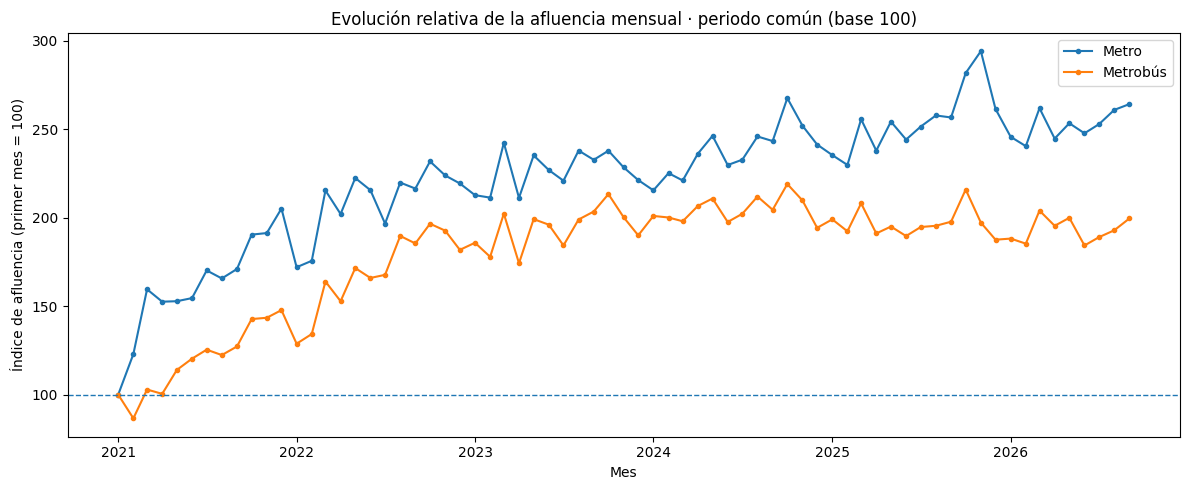

**Interpretación.** Entre **2021-01** y **2026-09**, Metro termina **+164.1%** respecto del primer mes y Metrobús **+99.5%**. La correlación mensual entre ambos volúmenes es **r = 0.912**.  
**Relevancia.** Permite detectar movimientos compartidos o divergencias entre sistemas en una escala comparable.  
**Limitación.** El índice oculta las diferencias absolutas de tamaño y la correlación no implica causalidad.

In [45]:
def serie_mensual(df, nombre):
    return (df.groupby('mes_calc', as_index=False)['afluencia'].sum()
              .rename(columns={'afluencia': nombre}))

metro_mes = serie_mensual(metro, 'Metro')
mb_mes = serie_mensual(metrobus, 'Metrobús')
comparacion = metro_mes.merge(mb_mes, on='mes_calc', how='inner').sort_values('mes_calc').dropna()

for col in ['Metro', 'Metrobús']:
    comparacion[f'{col}_indice'] = comparacion[col] / comparacion[col].iloc[0] * 100

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(comparacion['mes_calc'], comparacion['Metro_indice'], marker='o', markersize=3, label='Metro')
ax.plot(comparacion['mes_calc'], comparacion['Metrobús_indice'], marker='o', markersize=3, label='Metrobús')
ax.axhline(100, linewidth=1, linestyle='--')
ax.set_title('Evolución relativa de la afluencia mensual · periodo común (base 100)')
ax.set_xlabel('Mes')
ax.set_ylabel('Índice de afluencia (primer mes = 100)')
ax.legend()
plt.tight_layout()
plt.show()

corr_sistemas = comparacion[['Metro', 'Metrobús']].corr().iloc[0, 1]
delta_metro = comparacion['Metro_indice'].iloc[-1] - 100
delta_mb = comparacion['Metrobús_indice'].iloc[-1] - 100

display(Markdown(
    f"**Interpretación.** Entre **{comparacion['mes_calc'].min():%Y-%m}** y **{comparacion['mes_calc'].max():%Y-%m}**, "
    f"Metro termina **{delta_metro:+.1f}%** respecto del primer mes y Metrobús **{delta_mb:+.1f}%**. "
    f"La correlación mensual entre ambos volúmenes es **r = {corr_sistemas:.3f}**.  \n"
    "**Relevancia.** Permite detectar movimientos compartidos o divergencias entre sistemas en una escala comparable.  \n"
    "**Limitación.** El índice oculta las diferencias absolutas de tamaño y la correlación no implica causalidad."
))


### Concentración de la afluencia por estación del Metro

#### Pregunta de investigación 3
**¿Qué tan concentrada está la demanda del Metro en sus estaciones con mayor afluencia?**

La visualización combina el volumen de las principales estaciones con su porcentaje acumulado sobre toda la afluencia observada.


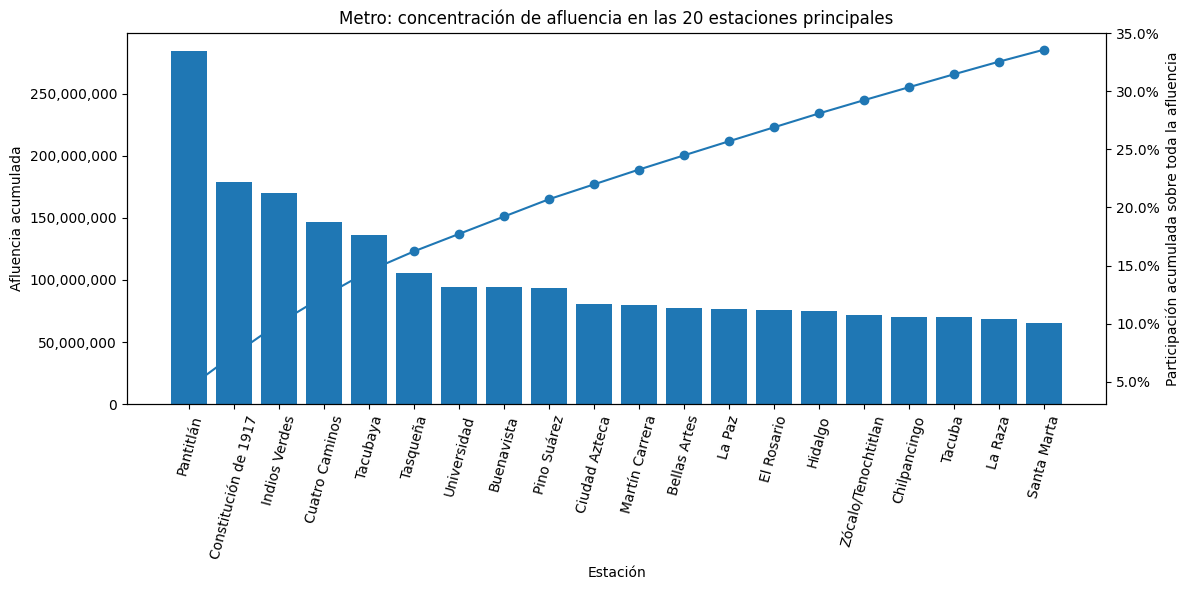

**Interpretación.** Las 20 estaciones con mayor volumen representan **33.6%** de la afluencia registrada. La estación líder es **Pantitlán**, con **284,750,916** accesos acumulados.  
**Relevancia.** La concentración ayuda a priorizar estaciones para análisis operativos y de capacidad.  
**Limitación.** Afluencia acumulada no equivale a saturación: faltan capacidad física, transbordos, accesos disponibles y oferta de trenes.

In [46]:
estaciones_metro = metro.groupby('estacion')['afluencia'].sum().sort_values(ascending=False)
pareto = estaciones_metro.head(20).to_frame('afluencia')
pareto['participacion'] = pareto['afluencia'] / estaciones_metro.sum()
pareto['acumulado'] = pareto['participacion'].cumsum()

fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.bar(pareto.index, pareto['afluencia'])
ax1.set_title('Metro: concentración de afluencia en las 20 estaciones principales')
ax1.set_xlabel('Estación')
ax1.set_ylabel('Afluencia acumulada')
ax1.tick_params(axis='x', rotation=75)
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

ax2 = ax1.twinx()
ax2.plot(pareto.index, pareto['acumulado'], marker='o')
ax2.set_ylabel('Participación acumulada sobre toda la afluencia')
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.grid(False)
plt.tight_layout()
plt.show()

share20 = pareto['participacion'].sum()
lider_est = estaciones_metro.index[0]
display(Markdown(
    f"**Interpretación.** Las 20 estaciones con mayor volumen representan **{share20:.1%}** de la afluencia registrada. "
    f"La estación líder es **{lider_est}**, con **{estaciones_metro.iloc[0]:,.0f}** accesos acumulados.  \n"
    "**Relevancia.** La concentración ayuda a priorizar estaciones para análisis operativos y de capacidad.  \n"
    "**Limitación.** Afluencia acumulada no equivale a saturación: faltan capacidad física, transbordos, accesos disponibles y oferta de trenes."
))


### Contexto histórico multimodal del transporte público

#### Pregunta de investigación 4
**¿Cómo se comporta la afluencia mensual de los principales organismos de transporte en el histórico disponible?**

Esta sección incorpora la tercera fuente preparada al inicio, `Afluencia_TP_historico`, para ubicar Metro y Metrobús dentro de un contexto de movilidad pública más amplio.


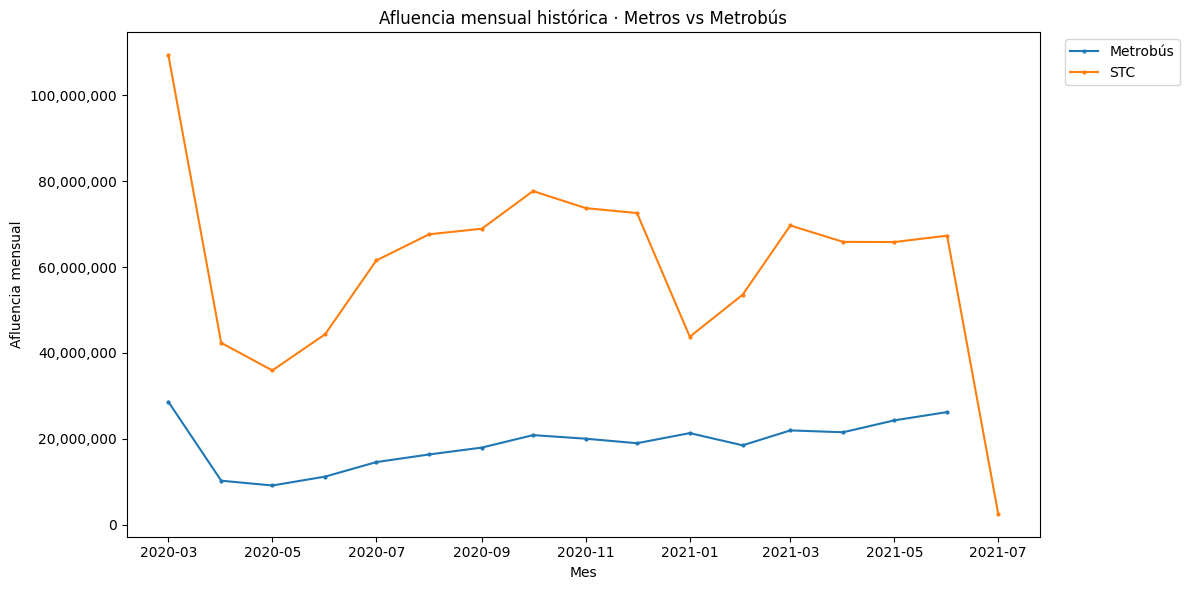

**Interpretación.** En el acumulado del histórico, **STC** registra el mayor volumen entre los organismos disponibles. Las trayectorias mensuales permiten identificar periodos de caída, recuperación o divergencia entre modos.  
**Relevancia.** Evita analizar Metro y Metrobús como sistemas aislados del ecosistema de transporte público.  
**Limitación.** La fuente es preliminar y presenta valores faltantes; además, la cobertura y el nivel de desagregación pueden variar entre organismos.

In [47]:
hist_valid = historico.dropna(subset=['mes_calc', 'organismo', 'afluencia_total_preliminar']).copy()
principales = (hist_valid.groupby('organismo')['afluencia_total_preliminar'].sum()
                        .nlargest(2).index.tolist())
hist_mes = (hist_valid[hist_valid['organismo'].isin(principales)]
            .groupby(['mes_calc', 'organismo'], as_index=False)['afluencia_total_preliminar'].sum())

fig, ax = plt.subplots(figsize=(12, 6))
for organismo, grp in hist_mes.groupby('organismo'):
    ax.plot(grp['mes_calc'], grp['afluencia_total_preliminar'], marker='o', markersize=2, label=organismo)
ax.set_title('Afluencia mensual histórica · Metros vs Metrobús')
ax.set_xlabel('Mes')
ax.set_ylabel('Afluencia mensual')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

lider_hist = (hist_valid.groupby('organismo')['afluencia_total_preliminar'].sum().idxmax())
display(Markdown(
    f"**Interpretación.** En el acumulado del histórico, **{lider_hist}** registra el mayor volumen entre los organismos disponibles. "
    "Las trayectorias mensuales permiten identificar periodos de caída, recuperación o divergencia entre modos.  \n"
    "**Relevancia.** Evita analizar Metro y Metrobús como sistemas aislados del ecosistema de transporte público.  \n"
    "**Limitación.** La fuente es preliminar y presenta valores faltantes; además, la cobertura y el nivel de desagregación pueden variar entre organismos."
))


### Evolución conjunta de afluencia e ingresos del Metro

#### Pregunta de investigación 5
**¿Cuál es la evolución conjunta entre la afluencia del Metro y los ingresos reportados por el STC?**

Las dos fuentes no cubren exactamente el mismo periodo. Por ello se agregan por mes y se restringe el análisis al **intervalo temporal común** antes de comparar.


Periodo común: 2021-01 a 2023-07 | 31 meses


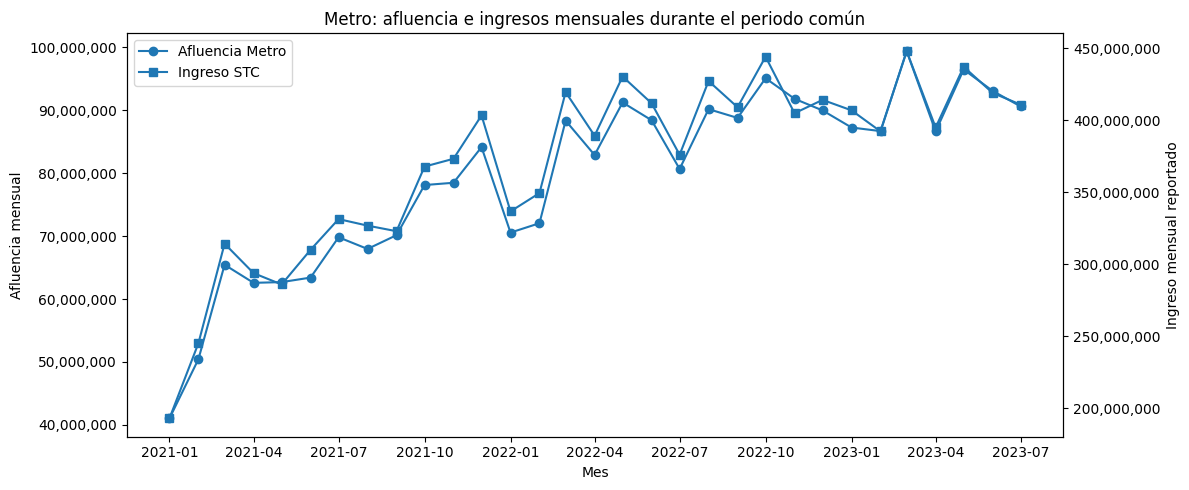

**Interpretación.** Durante el periodo común, la correlación de Pearson entre afluencia e ingreso mensual es **r = 0.991**.  
**Relevancia.** Permite evaluar si los meses de mayor utilización tienden a coincidir con mayores ingresos reportados.  
**Limitación.** La asociación no demuestra causalidad y puede estar afectada por tarifas, gratuidades, recargas anticipadas, descuentos e inflación.

In [48]:
# Usamos la tabla mensual ya unida y verificada en la manipulación (metro_ingresos_mes)
comun = (metro_ingresos_mes.assign(mes_calc=pd.to_datetime(metro_ingresos_mes['mes']))
                           .rename(columns={'pasajeros': 'afluencia_metro'})
                           .sort_values('mes_calc'))

print(f"Periodo común: {comun['mes_calc'].min():%Y-%m} a {comun['mes_calc'].max():%Y-%m} | {len(comun)} meses")

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(comun['mes_calc'], comun['afluencia_metro'], marker='o', label='Afluencia Metro')
ax1.set_xlabel('Mes')
ax1.set_ylabel('Afluencia mensual')
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

ax2 = ax1.twinx()
ax2.plot(comun['mes_calc'], comun['ingreso_total'], marker='s', label='Ingreso STC')
ax2.set_ylabel('Ingreso mensual reportado')
ax2.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
ax2.grid(False)
ax1.set_title('Metro: afluencia e ingresos mensuales durante el periodo común')

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left')
plt.tight_layout()
plt.show()

corr_total = comun[['afluencia_metro', 'ingreso_total']].corr().iloc[0, 1]
display(Markdown(
    f"**Interpretación.** Durante el periodo común, la correlación de Pearson entre afluencia e ingreso mensual es "
    f"**r = {corr_total:.3f}**.  \n"
    "**Relevancia.** Permite evaluar si los meses de mayor utilización tienden a coincidir con mayores ingresos reportados.  \n"
    "**Limitación.** La asociación no demuestra causalidad y puede estar afectada por tarifas, gratuidades, recargas anticipadas, descuentos e inflación."
))


## 4.2 Ecobici

In [49]:
plt.rcParams.update({'figure.figsize':(11,5.5),'axes.titlesize':14,'axes.labelsize':11,'figure.dpi':110})

# Archivos de Ecobici que no se usaron en la limpieza (misma carpeta DATA_DIR)
ARCHIVOS = {
    'estaciones': DATA_DIR / 'Ubicación de estaciones ecobici.csv',
    'diarios': DATA_DIR / 'Viajes diarios del sistema Ecobici.csv',
    'mensuales': DATA_DIR / 'Viajes mensuales desglosados del sistema Ecobici.csv',
}

### Preparación para visualizar

La limpieza exhaustiva corresponde a su módulo específico. Aquí solo se crean tipos y variables derivadas indispensables para las visualizaciones; las fuentes originales no se modifican.


In [50]:
diarios = pd.read_csv(ARCHIVOS['diarios'], low_memory=False)
mensuales = pd.read_csv(ARCHIVOS['mensuales'], low_memory=False)
estaciones = pd.read_csv(ARCHIVOS['estaciones'], low_memory=False)

diarios['fecha'] = pd.to_datetime(diarios['fecha'], errors='coerce')
diarios['genero'] = diarios['genero'].fillna('No especificado')
dias_es = {0:'Lunes',1:'Martes',2:'Miércoles',3:'Jueves',4:'Viernes',5:'Sábado',6:'Domingo'}

mensuales['fecha_corte'] = pd.to_datetime(mensuales['fecha_corte'], errors='coerce')
mensuales['genero'] = mensuales['genero'].fillna('No especificado')
mensuales['hora_num'] = pd.to_numeric(mensuales['hora'].astype(str).str.extract(r'(^\d{1,2})')[0], errors='coerce')
mensuales['rango_edad_std'] = (mensuales['rango_edad'].astype('string').str.replace(r'\s*-\s*','-',regex=True).str.strip().fillna('No especificado'))

estaciones['estacion_id'] = pd.to_numeric(estaciones['num_cicloestacion'], errors='coerce').astype('Int64').astype('string')
# Identificador y descripción para etiquetar las estaciones en los gráficos.
# Si el catálogo no incluye un nombre, se utiliza el identificador.
columnas_nombre = [c for c in estaciones.columns if c.lower() in {
    'nombre', 'nombre_estacion', 'nombre_cicloestacion', 'cicloestacion',
    'estacion', 'direccion', 'ubicacion', 'ubicación'
}]
if columnas_nombre:
    nombre_map = (estaciones.dropna(subset=['estacion_id'])
                  .drop_duplicates('estacion_id')
                  .set_index('estacion_id')[columnas_nombre[0]]
                  .astype('string').to_dict())
else:
    nombre_map = {}


resumen = pd.DataFrame({'fuente':['Viajes diarios','Viajes mensuales','Estaciones'],
                        'filas':[len(diarios),len(mensuales),len(estaciones)],
                        'columnas':[diarios.shape[1],mensuales.shape[1],estaciones.shape[1]]})
display(resumen)


,fuente,filas,columnas
0,Viajes diarios,12261,5
1,Viajes mensuales,115773,9
2,Estaciones,480,12


In [51]:
# Viajes de enero 2026: usamos los viajes válidos de la limpieza (sin duraciones > 24 h ni retiros antes de enero)
def id_est(s): return pd.to_numeric(s, errors='coerce').astype('Int64').astype('string')

detalle = ecobici_validos.copy()
detalle['origen_id'] = id_est(detalle['Ciclo_Estacion_Retiro'])
detalle['destino_id'] = id_est(detalle['Ciclo_EstacionArribo'])
print('Viajes de enero 2026 usados:', len(detalle))

Viajes de enero 2026 usados: 1525178


---
### Pregunta 6 · ¿Cómo ha evolucionado el número de viajes de ECOBICI entre 2010 y 2024?

**Tipo:** línea temporal para identificar crecimiento, caídas y cambios de tendencia.


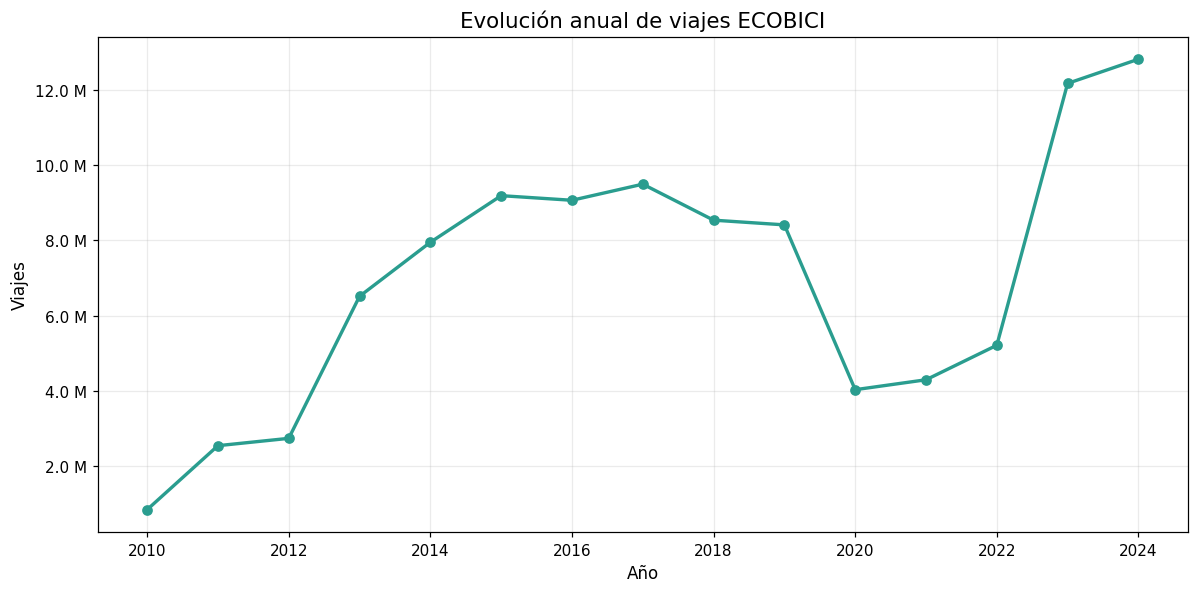

**Interpretación.** El mayor volumen anual observado se registra en **2024**, con **12.82 millones** de viajes. El último año observado es **2024**, con registros hasta **2024-07-31**; debe verificarse su cobertura antes de compararlo con años completos.  


In [52]:
viajes_anuales = diarios.assign(anio=diarios['fecha'].dt.year).groupby('anio', as_index=False)['viajes'].sum()
fig,ax=plt.subplots(); ax.plot(viajes_anuales.anio,viajes_anuales.viajes,marker='o',lw=2.2,color=COL['verde'])
ax.set(title='Evolución anual de viajes ECOBICI',xlabel='Año',ylabel='Viajes'); ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,p:f'{x/1e6:.1f} M')); ax.grid(alpha=.25); plt.tight_layout(); plt.show()
r=viajes_anuales.loc[viajes_anuales.viajes.idxmax()]; fin=viajes_anuales.iloc[-1]
display(Markdown(f"""**Interpretación.** El mayor volumen anual observado se registra en **{int(r.anio)}**, con **{r.viajes/1e6:.2f} millones** de viajes. El último año observado es **{int(fin.anio)}**, con registros hasta **{diarios.fecha.max().date()}**; debe verificarse su cobertura antes de compararlo con años completos.  
"""))


---
### Pregunta 7 · En 2024, ¿qué días de la semana concentran más viajes diarios?

**Tipo:** barras con promedio diario por día de la semana.


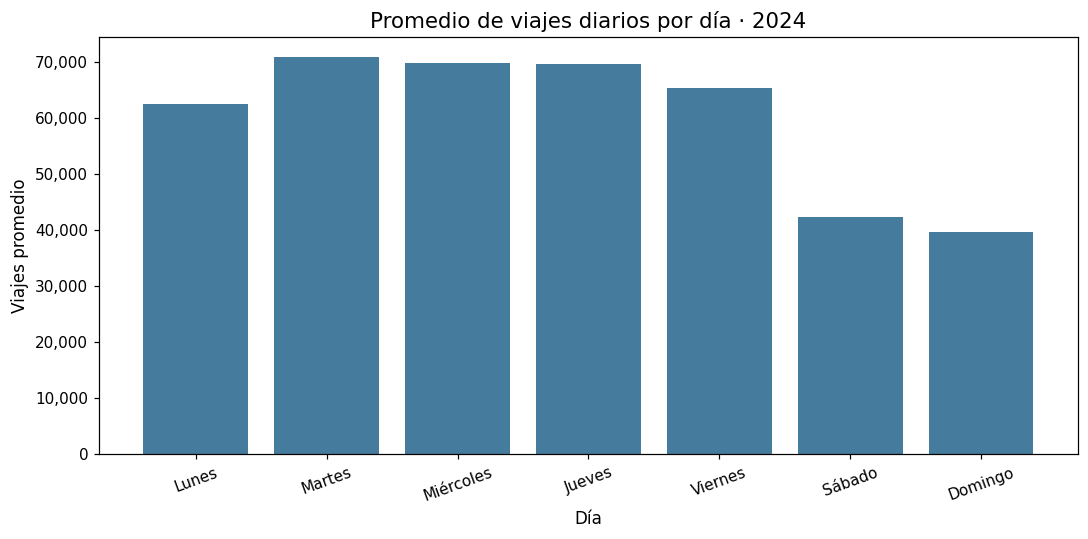

**Interpretación.** **Martes** presenta el mayor promedio (70,947) y **Domingo** el menor (39,650); la diferencia es **78.9%**.  
**Relevancia.** Distingue patrones laborales y de fin de semana.  
**Limitación.** La cobertura para 2024 debe verificarse: su última fecha registrada es 2024-07-31. Días festivos y días sin registro pueden modificar el promedio.

In [53]:
d2024=diarios[diarios.fecha.dt.year.eq(2024)].groupby('fecha',as_index=False).viajes.sum(); d2024['dia_num']=d2024.fecha.dt.dayofweek; d2024['dia']=d2024.dia_num.map(dias_es)
w=d2024.groupby(['dia_num','dia'],as_index=False).viajes.mean().sort_values('dia_num')
fig,ax=plt.subplots(figsize=(10,5)); ax.bar(w.dia,w.viajes,color=COL['azul']); ax.set(title='Promedio de viajes diarios por día · 2024',xlabel='Día',ylabel='Viajes promedio'); ax.tick_params(axis='x',rotation=20); ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}')); plt.tight_layout(); plt.show()
a=w.loc[w.viajes.idxmax()]; b=w.loc[w.viajes.idxmin()]; pct=(a.viajes/b.viajes-1)*100
display(Markdown(f"""**Interpretación.** **{a.dia}** presenta el mayor promedio ({a.viajes:,.0f}) y **{b.dia}** el menor ({b.viajes:,.0f}); la diferencia es **{pct:.1f}%**.  
**Relevancia.** Distingue patrones laborales y de fin de semana.  
**Limitación.** La cobertura para 2024 debe verificarse: su última fecha registrada es {d2024.fecha.max().date() if not d2024.empty else "no disponible"}. Días festivos y días sin registro pueden modificar el promedio."""))


---
### Pregunta 8 · ¿Cómo ha cambiado la composición de viajes por género?

**Tipo:** líneas de participación porcentual anual para comparar composición sin que domine el crecimiento total.


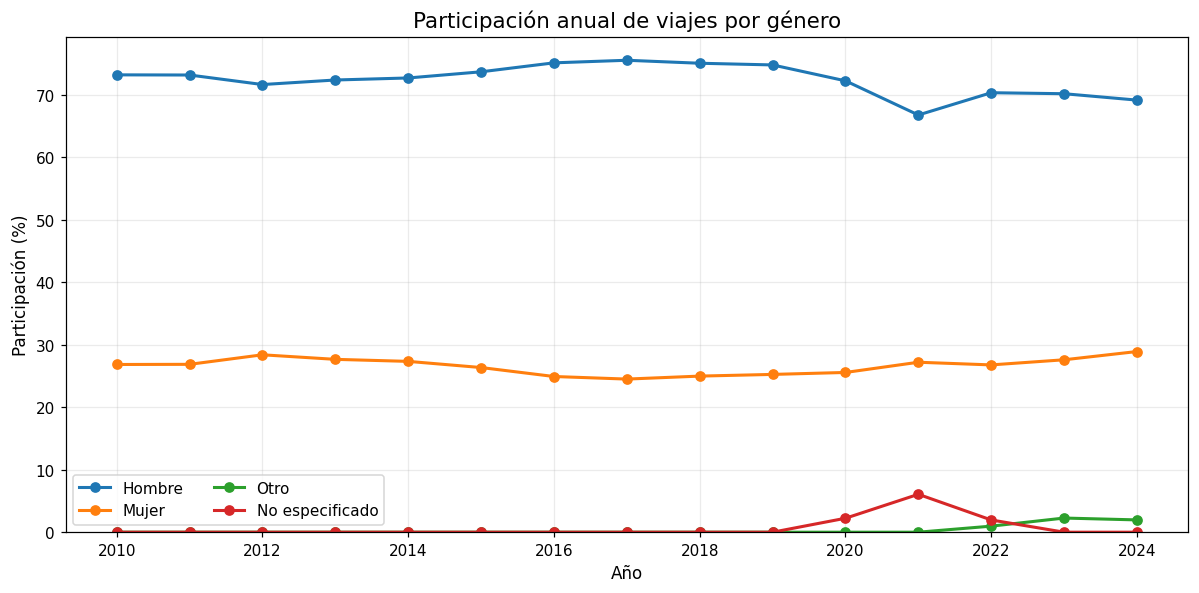

**Interpretación.** En 2024, la composición observada es **Hombre: 69.1%, Mujer: 28.9%, Otro: 2.0%, No especificado: 0.0%**.  
**Relevancia.** Permite ver si el crecimiento del sistema se acompaña de cambios en los grupos registrados.  
**Limitación.** Hay registros no especificados y la variable no permite inferir identidad, motivos de viaje ni barreras de acceso.

In [54]:
ga=diarios.assign(anio=diarios.fecha.dt.year).groupby(['anio','genero'],as_index=False).viajes.sum(); gp=ga.pivot(index='anio',columns='genero',values='viajes').fillna(0); sh=gp.div(gp.sum(axis=1),axis=0)*100
fig,ax=plt.subplots();
for col in [x for x in ['Hombre','Mujer','Otro','No especificado'] if x in sh.columns]: ax.plot(sh.index,sh[col],marker='o',lw=2,label=col)
ax.set(title='Participación anual de viajes por género',xlabel='Año',ylabel='Participación (%)'); ax.set_ylim(bottom=0); ax.legend(ncol=2); ax.grid(alpha=.25); plt.tight_layout(); plt.show()
u=sh.loc[sh.index.max()].sort_values(ascending=False); txt=', '.join(f'{k}: {v:.1f}%' for k,v in u.items())
display(Markdown(f"""**Interpretación.** En {sh.index.max()}, la composición observada es **{txt}**.  
**Relevancia.** Permite ver si el crecimiento del sistema se acompaña de cambios en los grupos registrados.  
**Limitación.** Hay registros no especificados y la variable no permite inferir identidad, motivos de viaje ni barreras de acceso."""))


---
### Pregunta 9 · ¿Qué grupos de edad concentran más viajes en el histórico disponible?

**Tipo:** barras horizontales por rango de edad.


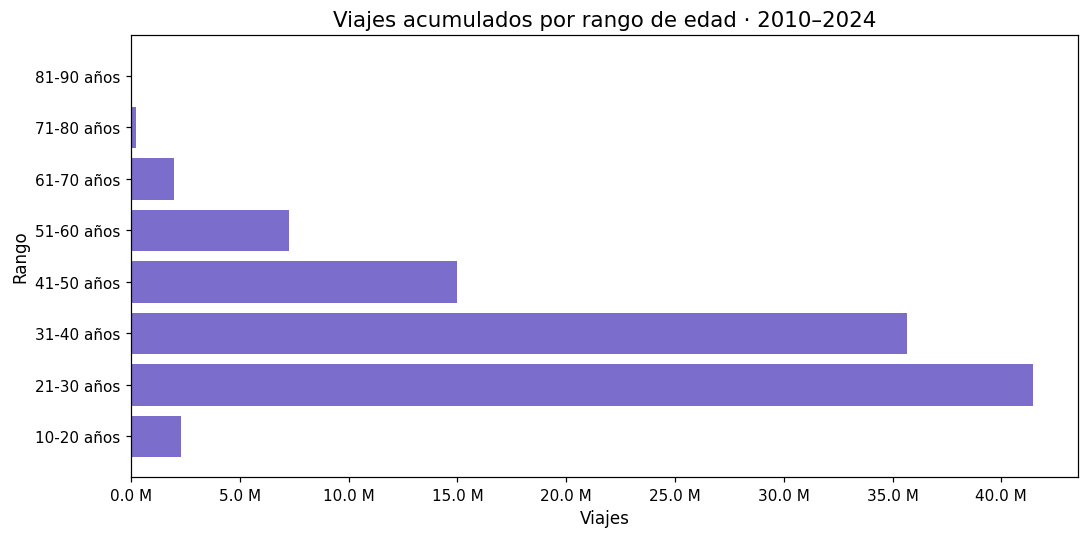

**Interpretación.** El rango **21-30 años** concentra el mayor volumen acumulado: **41.45 millones** de viajes.  
**Relevancia.** Identifica segmentos etarios con mayor presencia observada.  


In [55]:
eh=mensuales[mensuales.rango_edad_std.ne('No especificado')].groupby('rango_edad_std',as_index=False).viajes.sum()
def inicio(x):
    try:return int(str(x).split('-')[0])
    except:return 999
eh['orden']=eh.rango_edad_std.map(inicio); eh=eh.sort_values('orden')
fig,ax=plt.subplots(figsize=(10,5)); ax.barh(eh.rango_edad_std,eh.viajes,color=COL['morado']); ax.set(title='Viajes acumulados por rango de edad · 2010–2024',xlabel='Viajes',ylabel='Rango'); ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,p:f'{x/1e6:.1f} M')); plt.tight_layout(); plt.show()
r=eh.loc[eh.viajes.idxmax()]
display(Markdown(f"""**Interpretación.** El rango **{r.rango_edad_std}** concentra el mayor volumen acumulado: **{r.viajes/1e6:.2f} millones** de viajes.  
**Relevancia.** Identifica segmentos etarios con mayor presencia observada.  
"""))


---
### Pregunta 10 · ¿A qué horas se concentra la demanda y difiere el perfil horario por género?

**Tipo:** líneas por hora del día usando 2024.


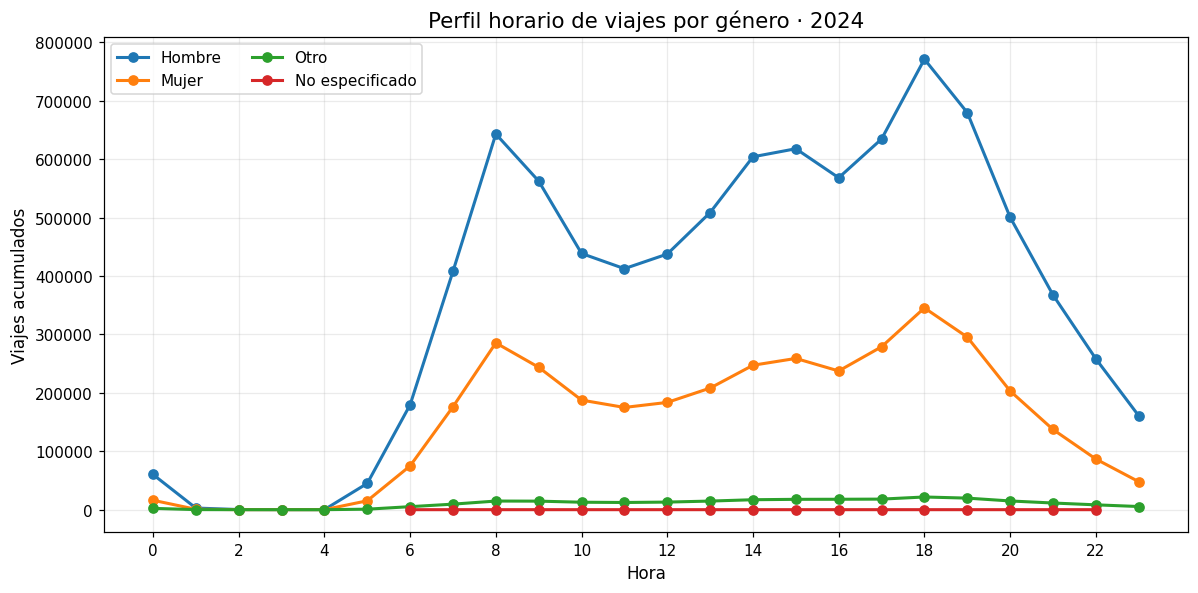

**Interpretación.** La hora con mayor volumen agregado en 2024 es alrededor de las **18:00**.  
**Relevancia.** Los picos horarios son centrales para redistribución y capacidad.  


In [56]:
mh=mensuales[mensuales.anio.eq(2024)&mensuales.hora_num.between(0,23)].groupby(['hora_num','genero'],as_index=False).viajes.sum()
fig,ax=plt.subplots();
for g in ['Hombre','Mujer','Otro','No especificado']:
    a=mh[mh.genero.eq(g)]
    if len(a): ax.plot(a.hora_num,a.viajes,marker='o',lw=2,label=g)
ax.set(title='Perfil horario de viajes por género · 2024',xlabel='Hora',ylabel='Viajes acumulados'); ax.set_xticks(range(0,24,2)); ax.legend(ncol=2); ax.grid(alpha=.25); plt.tight_layout(); plt.show()
h=mh.groupby('hora_num').viajes.sum(); hp=int(h.idxmax())
display(Markdown(f"""**Interpretación.** La hora con mayor volumen agregado en 2024 es alrededor de las **{hp:02d}:00**.  
**Relevancia.** Los picos horarios son centrales para redistribución y capacidad.  
"""))


---
### Pregunta 11 · ¿Cómo se distribuye la capacidad de estaciones entre alcaldías?

**Tipo:** barras de candados totales con número de estaciones.


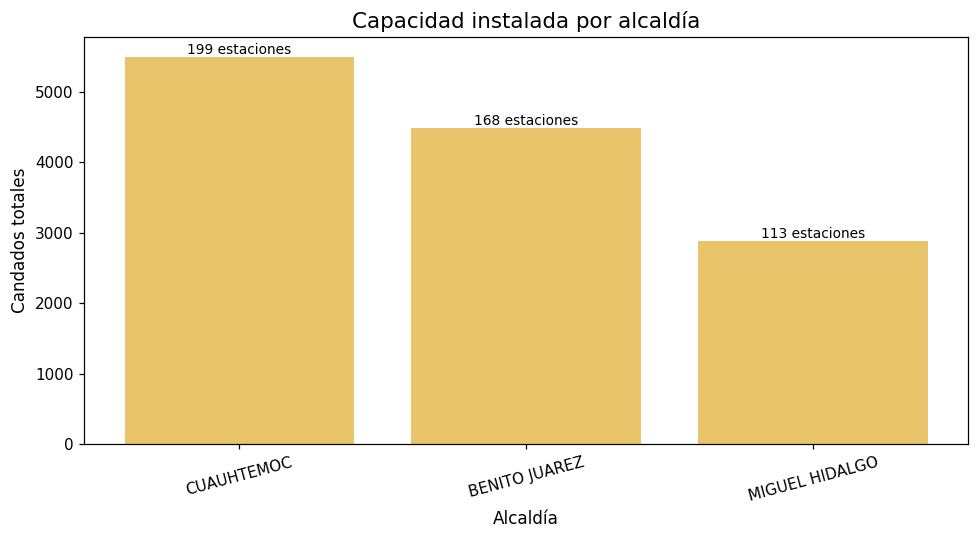

**Interpretación.** **CUAUHTEMOC** concentra la mayor capacidad del catálogo: **5,496 candados** en **199 estaciones**.  
**Relevancia.** La capacidad física condiciona retiros y arribos potenciales.  
**Limitación.** El catálogo contiene 480 estaciones en 3 alcaldías, mientras el archivo 2026 observa más códigos; la cobertura geográfica no es completa para toda la red 2026.

In [57]:
infra=estaciones.groupby('alcaldia',as_index=False).agg(estaciones=('num_cicloestacion','count'),candados=('candados','sum'),candados_promedio=('candados','mean')).sort_values('candados',ascending=False)
fig,ax=plt.subplots(figsize=(9,5)); bars=ax.bar(infra.alcaldia,infra.candados,color=COL['amarillo']); ax.set(title='Capacidad instalada por alcaldía',xlabel='Alcaldía',ylabel='Candados totales'); ax.tick_params(axis='x',rotation=15)
for b,n in zip(bars,infra.estaciones): ax.text(b.get_x()+b.get_width()/2,b.get_height(),f'{n} estaciones',ha='center',va='bottom',fontsize=9)
plt.tight_layout(); plt.show(); r=infra.iloc[0]
display(Markdown(f"""**Interpretación.** **{r.alcaldia}** concentra la mayor capacidad del catálogo: **{int(r.candados):,} candados** en **{int(r.estaciones)} estaciones**.  
**Relevancia.** La capacidad física condiciona retiros y arribos potenciales.  
**Limitación.** El catálogo contiene {len(estaciones)} estaciones en {estaciones.alcaldia.nunique()} alcaldías, mientras el archivo 2026 observa más códigos; la cobertura geográfica no es completa para toda la red 2026."""))


---
### Pregunta 12 · ¿Qué estaciones presentan mayor desequilibrio entre arribos y retiros?

**Tipo:** barras divergentes del balance `arribos − retiros`.


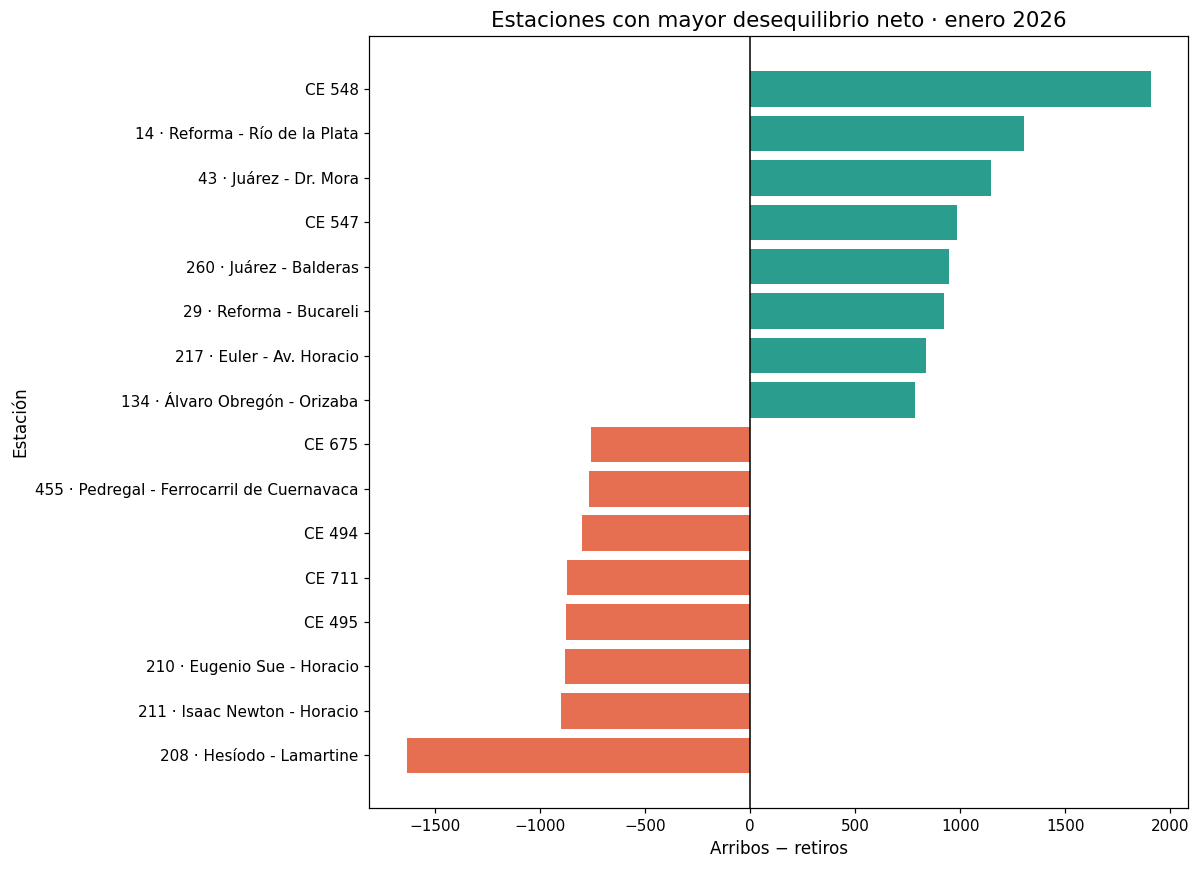

**Interpretación.** Mayor saldo positivo: **CE 548** (+1,907); mayor saldo negativo: **208 · Hesíodo - Lamartine** (-1,634).  
**Relevancia.** Aproxima la presión de redistribución de bicicletas.  
**Limitación.** Es un balance mensual; no indica la hora del desbalance ni movimientos logísticos del operador.

In [58]:
sal=detalle.groupby('origen_id').size().rename('retiros'); ent=detalle.groupby('destino_id').size().rename('arribos'); bal=pd.concat([sal,ent],axis=1).fillna(0); bal['neto']=bal.arribos-bal.retiros; bal=bal.reset_index().rename(columns={'index':'estacion_id'}); bal['nombre']=bal.estacion_id.map(nombre_map); bal['etiqueta']=np.where(bal.nombre.notna(),bal.estacion_id+' · '+bal.nombre.astype(str),'CE '+bal.estacion_id.astype(str)); ex=pd.concat([bal.nsmallest(8,'neto'),bal.nlargest(8,'neto')]).drop_duplicates('estacion_id').sort_values('neto')
fig,ax=plt.subplots(figsize=(11,8)); colors=[COL['rojo'] if x<0 else COL['verde'] for x in ex.neto]; ax.barh(ex.etiqueta,ex.neto,color=colors); ax.axvline(0,color='black',lw=1); ax.set(title='Estaciones con mayor desequilibrio neto · enero 2026',xlabel='Arribos − retiros',ylabel='Estación'); plt.tight_layout(); plt.show(); pos=bal.loc[bal.neto.idxmax()]; neg=bal.loc[bal.neto.idxmin()]
display(Markdown(f"""**Interpretación.** Mayor saldo positivo: **{pos.etiqueta}** (+{int(pos.neto):,}); mayor saldo negativo: **{neg.etiqueta}** ({int(neg.neto):,}).  
**Relevancia.** Aproxima la presión de redistribución de bicicletas.  
**Limitación.** Es un balance mensual; no indica la hora del desbalance ni movimientos logísticos del operador."""))


# 5. Interpretación y conclusiones
